# 2026-10-08 标注来源更正
旧步数、触球帧和守门员种子标签由AI助手生成，并非用户或独立真人标注。当前真人确认步数参考为0条。
旧版manual/confirmed命名、历史文本及输出不能作为真人复核证据；基于这些候选的准确率、MAE、RMSE结论撤回。
候选值已保留，确认字段为空；详见 docs/vision2_optimization_audit_2026-10-08.md。
守门员/足球脚本如需复用未验证输入，须显式添加 --allow-unverified-annotations，并标为探索实验。


In [8]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

pose_model = YOLO(str(PROJECT_ROOT / "models" / "weights" / "yolo11n_pose.pt"))
det_model = YOLO(str(PROJECT_ROOT / "models" / "weights" / "yolo11n_object_detection.pt"))

print("Models loaded.")

Models loaded.


In [9]:
clips_dir = PROJECT_ROOT / "data" / "raw_clips"

videos = sorted(clips_dir.glob("*.mp4"))

print(f"找到 {len(videos)} 个视频")

for video in videos[:10]:
    print(video)

找到 49 个视频
data\raw_clips\col_eng_p01_falcao_col9.mp4
data\raw_clips\col_eng_p02_kane.mp4
data\raw_clips\col_eng_p02_kane_eng9.mp4
data\raw_clips\col_eng_p03_cuadrado.mp4
data\raw_clips\col_eng_p03_cuadrado_col11.mp4
data\raw_clips\col_eng_p04_rashford.mp4
data\raw_clips\col_eng_p04_rashford_eng19.mp4
data\raw_clips\col_eng_p05_muriel.mp4
data\raw_clips\col_eng_p05_muriel_col14.mp4
data\raw_clips\col_eng_p06_henderson.mp4


In [10]:
video_path = str(videos[0])

print("测试视频：", video_path)

测试视频： data\raw_clips\col_eng_p01_falcao_col9.mp4


In [11]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = frame_count / fps

cap.release()

print("Video:", video_path)
print("FPS:", fps)
print("Frames:", frame_count)
print("Duration:", round(duration, 2), "seconds")

Video: data\raw_clips\col_eng_p01_falcao_col9.mp4
FPS: 30.0
Frames: 450
Duration: 15.0 seconds


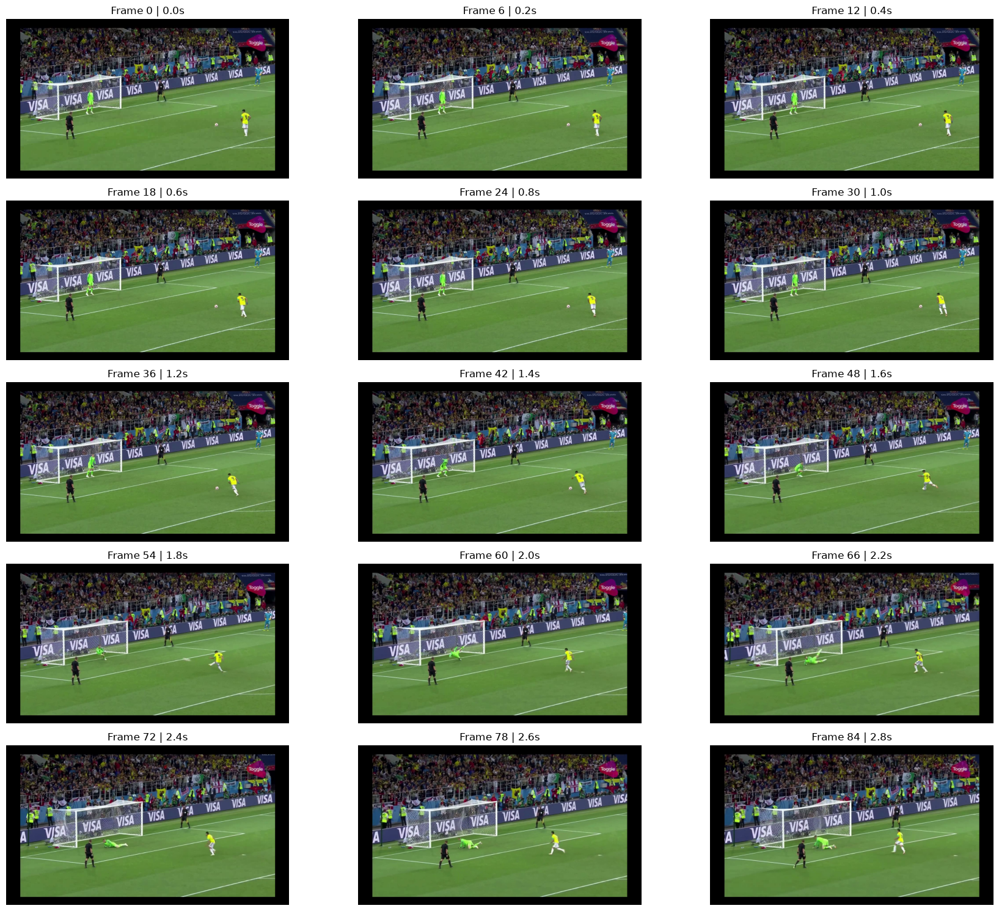

In [14]:
cap = cv2.VideoCapture(video_path)

# 只用于人工观察，不参与最终算法
sample_times = np.arange(0, 3.0, 0.2)

plt.figure(figsize=(18, 15))

for i, t in enumerate(sample_times):
    frame_id = int(t * fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        plt.subplot(5, 3, i + 1)
        plt.imshow(frame_rgb)
        plt.title(f"Frame {frame_id} | {t:.1f}s")
        plt.axis("off")

cap.release()

plt.tight_layout()
plt.show()

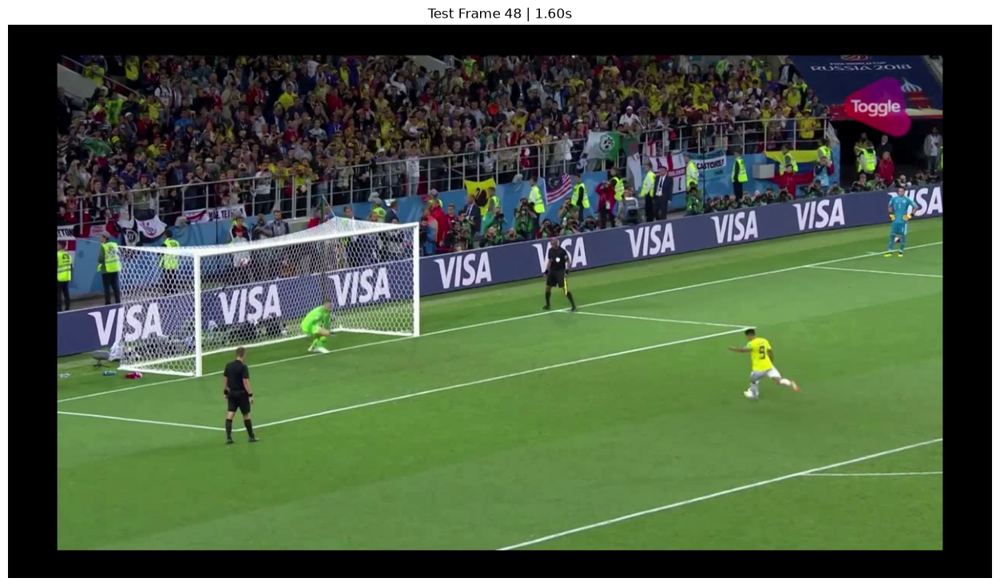

In [16]:
test_frame_id = 48

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, test_frame_id)

ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("无法读取测试帧")

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(
    f"Test Frame {test_frame_id} | "
    f"{test_frame_id / fps:.2f}s"
)
plt.axis("off")
plt.show()

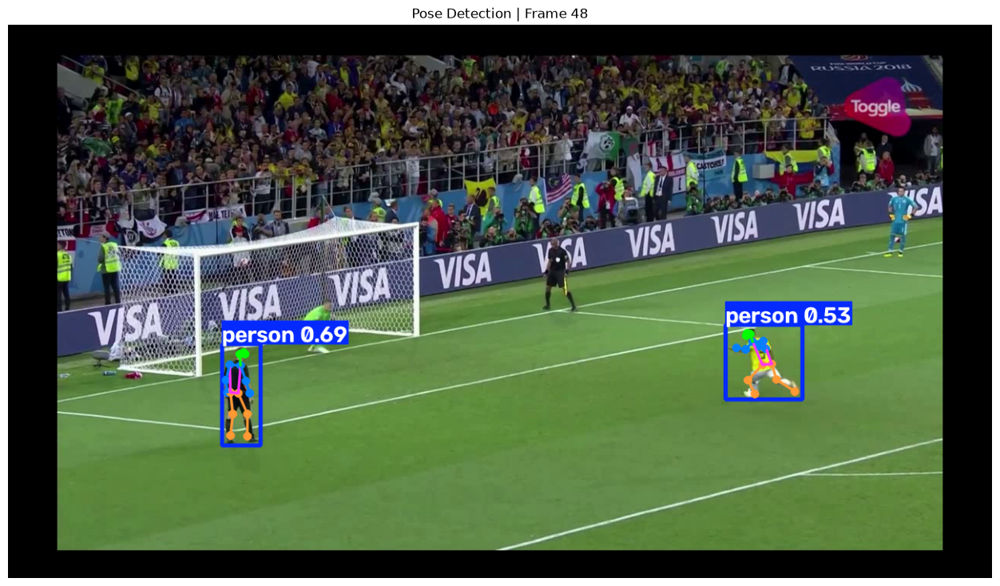

In [17]:
pose_results = pose_model(
    frame,
    conf=0.25,
    verbose=False
)

annotated_pose = pose_results[0].plot()

plt.figure(figsize=(16, 9))
plt.imshow(
    cv2.cvtColor(annotated_pose, cv2.COLOR_BGR2RGB)
)
plt.title(f"Pose Detection | Frame {test_frame_id}")
plt.axis("off")
plt.show()

In [22]:
result = pose_results[0]

# 获取人体框和关键点
boxes = result.boxes.xyxy.cpu().numpy()
keypoints = result.keypoints.xy.cpu().numpy()

print("检测到人数:", len(boxes))

# 打印每个人的位置
for i, box in enumerate(boxes):
    x1, y1, x2, y2 = box

    center_x = (x1 + x2) / 2
    center_y = (y1 + y2) / 2

    print(
        f"Person {i}: "
        f"center=({center_x:.1f}, {center_y:.1f})"
    )

# 当前 Falcao 测试：
# 主罚球员是检测到的人中最靠右的
centers_x = (boxes[:, 0] + boxes[:, 2]) / 2

kicker_idx = np.argmax(centers_x)

# 保存 kicker 的框和关键点
kicker_box = boxes[kicker_idx]
kicker_keypoints = keypoints[kicker_idx]

print()
print("当前 kicker candidate:", kicker_idx)
print("Kicker box:", np.round(kicker_box, 1))

检测到人数: 2
Person 0: center=(303.3, 481.6)
Person 1: center=(983.4, 439.3)

当前 kicker candidate: 1
Kicker box: [      933.4       390.7      1033.5       487.9]


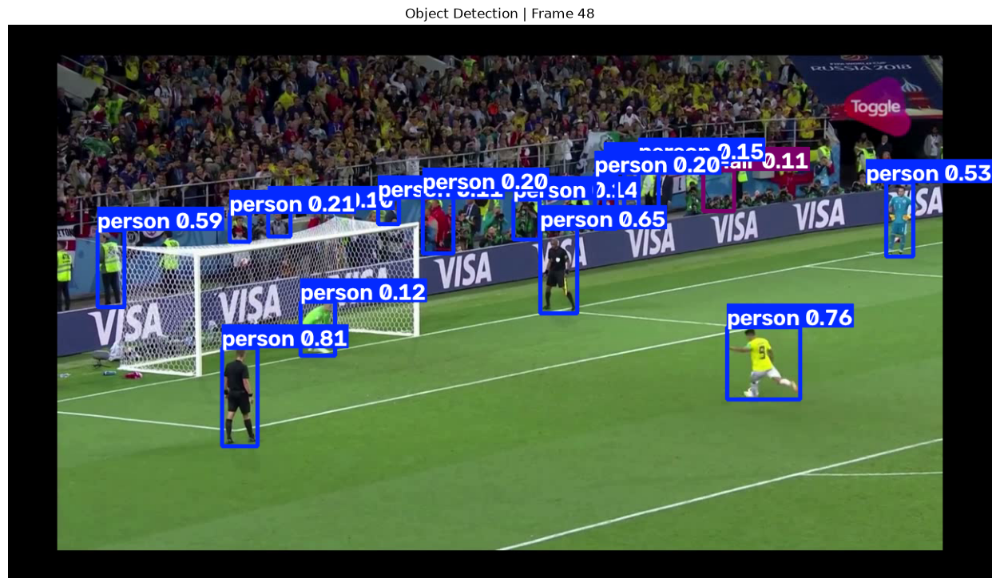

In [19]:
det_results = det_model(
    frame,
    conf=0.10,       # 足球很小，所以先降低阈值
    verbose=False
)

annotated_det = det_results[0].plot()

plt.figure(figsize=(16, 9))
plt.imshow(
    cv2.cvtColor(annotated_det, cv2.COLOR_BGR2RGB)
)
plt.title(f"Object Detection | Frame {test_frame_id}")
plt.axis("off")
plt.show()

Left ankle : [     971.64      480.42]
Right ankle: [     1023.1      477.73]


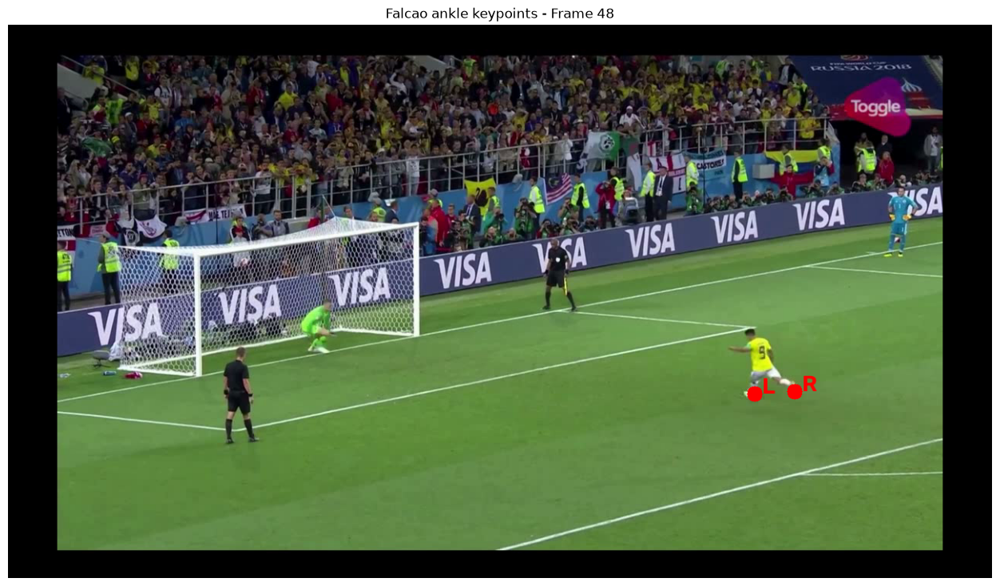

In [23]:
# COCO Pose:
# 15 = left ankle
# 16 = right ankle

left_ankle = kicker_keypoints[15]
right_ankle = kicker_keypoints[16]

print("Left ankle :", left_ankle)
print("Right ankle:", right_ankle)

ankle_frame = frame.copy()

for name, point in [
    ("L", left_ankle),
    ("R", right_ankle)
]:
    x, y = point.astype(int)

    cv2.circle(
        ankle_frame,
        (x, y),
        10,
        (0, 0, 255),
        -1
    )

    cv2.putText(
        ankle_frame,
        name,
        (x + 10, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 255),
        2
    )

plt.figure(figsize=(16, 9))
plt.imshow(
    cv2.cvtColor(ankle_frame, cv2.COLOR_BGR2RGB)
)
plt.title("Falcao ankle keypoints - Frame 48")
plt.axis("off")
plt.show()

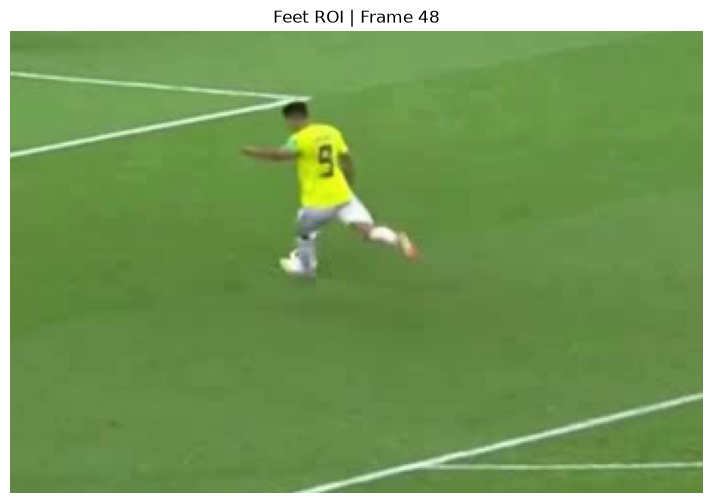

In [24]:
feet_center = (left_ankle + right_ankle) / 2
cx, cy = feet_center.astype(int)

# ROI 大小
half_width = 180
half_height = 120

h, w = frame.shape[:2]

x1 = max(0, cx - half_width)
x2 = min(w, cx + half_width)

y1 = max(0, cy - half_height)
y2 = min(h, cy + half_height)

feet_roi = frame[y1:y2, x1:x2]

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(feet_roi, cv2.COLOR_BGR2RGB))
plt.title(f"Feet ROI | Frame {test_frame_id}")
plt.axis("off")
plt.show()

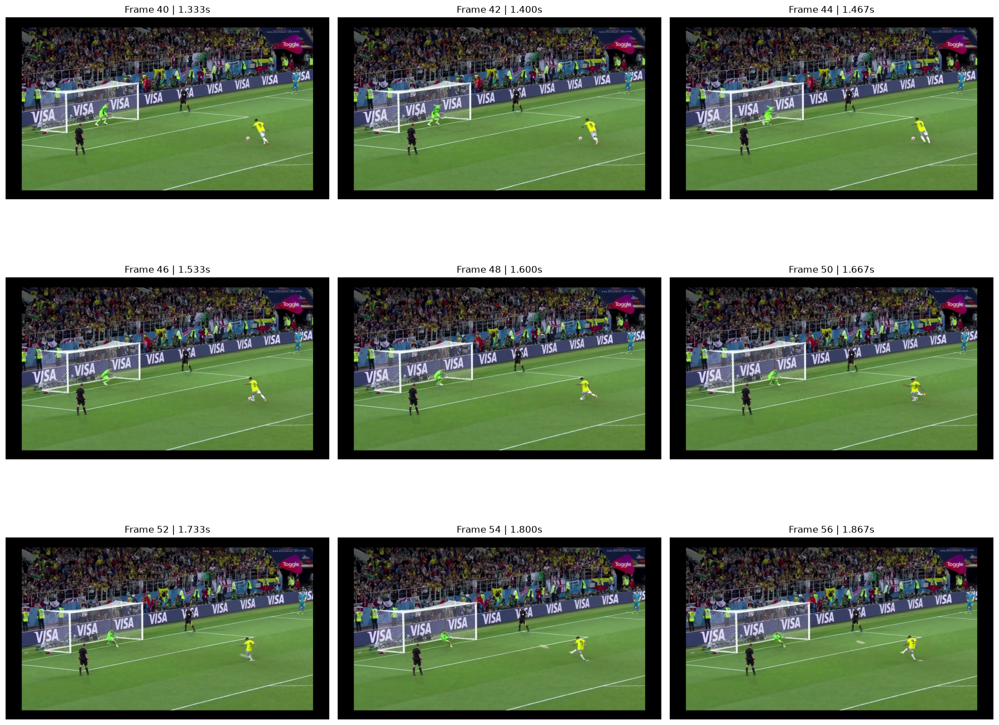

In [25]:
# 查看 kick 附近连续帧
start_frame = test_frame_id - 8
end_frame = test_frame_id + 8

cap = cv2.VideoCapture(video_path)

plt.figure(figsize=(18, 15))

plot_idx = 1

for fid in range(start_frame, end_frame + 1, 2):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    plt.subplot(3, 3, plot_idx)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(
        f"Frame {fid} | {fid / fps:.3f}s"
    )
    plt.axis("off")

    plot_idx += 1

cap.release()

plt.tight_layout()
plt.show()

In [28]:
start_frame = 40
end_frame = 60

cap = cv2.VideoCapture(video_path)

for fid in range(start_frame, end_frame + 1):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    result = pose_model(
        img,
        conf=0.25,
        verbose=False
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        print(fid, "No person")
        continue

    boxes = result.boxes.xyxy.cpu().numpy()

    centers_x = (
        boxes[:, 0] + boxes[:, 2]
    ) / 2

    kicker_idx = np.argmax(centers_x)

    center_x = centers_x[kicker_idx]

    print(
        f"Frame {fid:2d}: "
        f"persons={len(boxes):2d}, "
        f"selected={kicker_idx}, "
        f"x={center_x:.1f}"
    )

cap.release()

Frame 40: persons= 2, selected=1, x=1009.4
Frame 41: persons= 2, selected=1, x=997.0
Frame 42: persons= 2, selected=1, x=996.8
Frame 43: persons= 1, selected=0, x=297.3
Frame 44: persons= 2, selected=1, x=993.9
Frame 45: persons= 2, selected=1, x=987.4
Frame 46: persons= 2, selected=1, x=983.7
Frame 47: persons= 2, selected=1, x=983.4
Frame 48: persons= 2, selected=1, x=983.4
Frame 49: persons= 2, selected=1, x=974.7
Frame 50: persons= 2, selected=1, x=966.9
Frame 51: persons= 1, selected=0, x=309.1
Frame 52: persons= 2, selected=1, x=964.6
Frame 53: persons= 2, selected=1, x=958.4
Frame 54: persons= 2, selected=1, x=952.2
Frame 55: persons= 2, selected=1, x=947.3
Frame 56: persons= 2, selected=1, x=947.3
Frame 57: persons= 3, selected=2, x=958.4
Frame 58: persons= 2, selected=1, x=945.3
Frame 59: persons= 2, selected=1, x=945.8
Frame 60: persons= 2, selected=1, x=946.2


In [29]:
anchor_frame = 48

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, anchor_frame)
ret, anchor_img = cap.read()
cap.release()

anchor_result = pose_model(
    anchor_img,
    conf=0.25,
    verbose=False
)[0]

anchor_boxes = anchor_result.boxes.xyxy.cpu().numpy()

# Falcao 在 Frame 48 是最右侧 person
anchor_centers_x = (
    anchor_boxes[:, 0] + anchor_boxes[:, 2]
) / 2

anchor_idx = np.argmax(anchor_centers_x)

x1, y1, x2, y2 = anchor_boxes[anchor_idx]

anchor_center = np.array([
    (x1 + x2) / 2,
    (y1 + y2) / 2
])

print("Anchor kicker:", anchor_idx)
print("Anchor center:", anchor_center)

Anchor kicker: 1
Anchor center: [     983.44      439.28]


In [34]:
def find_closest_person(boxes, previous_center, max_move=80):
    """
    Find the person closest to the previous kicker position.

    If no detected person is close enough, return None.
    This prevents tracking from jumping to referee/spectators.
    """

    centers = np.column_stack([
        (boxes[:, 0] + boxes[:, 2]) / 2,
        (boxes[:, 1] + boxes[:, 3]) / 2
    ])

    distances = np.linalg.norm(
        centers - previous_center,
        axis=1
    )

    idx = np.argmin(distances)
    min_distance = distances[idx]

    # Tracking gate
    if min_distance > max_move:
        return None, None, min_distance

    return idx, centers[idx], min_distance

In [35]:
tracked = {}

previous_center = anchor_center.copy()

cap = cv2.VideoCapture(video_path)

for fid in range(48, 61):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    result = pose_model(
        img,
        conf=0.25,
        verbose=False
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        print(f"Frame {fid}: no person detected")
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    keypoints = result.keypoints.xy.cpu().numpy()

    idx, center, distance = find_closest_person(
        boxes,
        previous_center,
        max_move=80
    )

    # ---------------------------
    # Kicker temporarily missing
    # ---------------------------
    if idx is None:
        print(
            f"Frame {fid}: kicker missing "
            f"(nearest person = {distance:.1f}px)"
        )

        # IMPORTANT:
        # 不更新 previous_center
        continue

    # ---------------------------
    # Successful tracking
    # ---------------------------
    tracked[fid] = {
        "box": boxes[idx],
        "keypoints": keypoints[idx],
        "center": center
    }

    previous_center = center

    print(
        f"Frame {fid}: "
        f"person={idx}, "
        f"center=({center[0]:.1f}, {center[1]:.1f}), "
        f"move={distance:.1f}px"
    )

cap.release()

Frame 48: person=1, center=(983.4, 439.3), move=0.0px
Frame 49: person=1, center=(974.7, 441.6), move=9.1px
Frame 50: person=1, center=(966.9, 442.6), move=7.8px
Frame 51: kicker missing (nearest person = 659.0px)
Frame 52: person=1, center=(964.6, 440.9), move=2.9px
Frame 53: person=1, center=(958.4, 440.9), move=6.1px
Frame 54: person=1, center=(952.2, 440.1), move=6.3px
Frame 55: person=1, center=(947.3, 437.9), move=5.3px
Frame 56: person=1, center=(947.3, 438.0), move=0.0px
Frame 57: person=1, center=(944.4, 435.1), move=4.1px
Frame 58: person=1, center=(945.3, 434.1), move=1.4px
Frame 59: person=1, center=(945.8, 431.7), move=2.4px
Frame 60: person=1, center=(946.2, 432.7), move=1.1px


In [36]:
previous_center = anchor_center.copy()

cap = cv2.VideoCapture(video_path)

for fid in range(47, 39, -1):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    result = pose_model(
        img,
        conf=0.25,
        verbose=False
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    keypoints = result.keypoints.xy.cpu().numpy()

    idx, center, distance = find_closest_person(
        boxes,
        previous_center,
        max_move=80
    )

    if idx is None:
        print(
            f"Frame {fid}: kicker missing "
            f"(nearest={distance:.1f}px)"
        )
        continue

    tracked[fid] = {
        "box": boxes[idx],
        "keypoints": keypoints[idx],
        "center": center
    }

    previous_center = center

    print(
        f"Frame {fid}: "
        f"center=({center[0]:.1f}, {center[1]:.1f}), "
        f"move={distance:.1f}px"
    )

cap.release()

Frame 47: center=(983.4, 439.3), move=0.1px
Frame 46: center=(983.7, 443.4), move=4.1px
Frame 45: center=(987.4, 447.3), move=5.4px
Frame 44: center=(993.9, 448.5), move=6.6px
Frame 43: kicker missing (nearest=697.4px)
Frame 42: center=(996.8, 451.8), move=4.4px
Frame 41: center=(997.0, 451.9), move=0.1px
Frame 40: center=(1009.4, 451.9), move=12.4px


In [37]:
relative_data = []

for fid in sorted(tracked.keys()):

    kp = tracked[fid]["keypoints"]

    # COCO Pose keypoints
    left_hip = kp[11]
    right_hip = kp[12]
    left_ankle = kp[15]
    right_ankle = kp[16]

    # 排除缺失关键点
    points = [
        left_hip,
        right_hip,
        left_ankle,
        right_ankle
    ]

    if any(np.allclose(p, 0) for p in points):
        print(f"Frame {fid}: invalid keypoints")
        continue

    # 身体中心
    hip_center = (left_hip + right_hip) / 2

    # 脚踝相对于身体的位置
    left_relative = left_ankle - hip_center
    right_relative = right_ankle - hip_center

    relative_data.append({
        "frame": fid,
        "left_x": left_relative[0],
        "left_y": left_relative[1],
        "right_x": right_relative[0],
        "right_y": right_relative[1]
    })

print("有效帧数:", len(relative_data))

有效帧数: 19


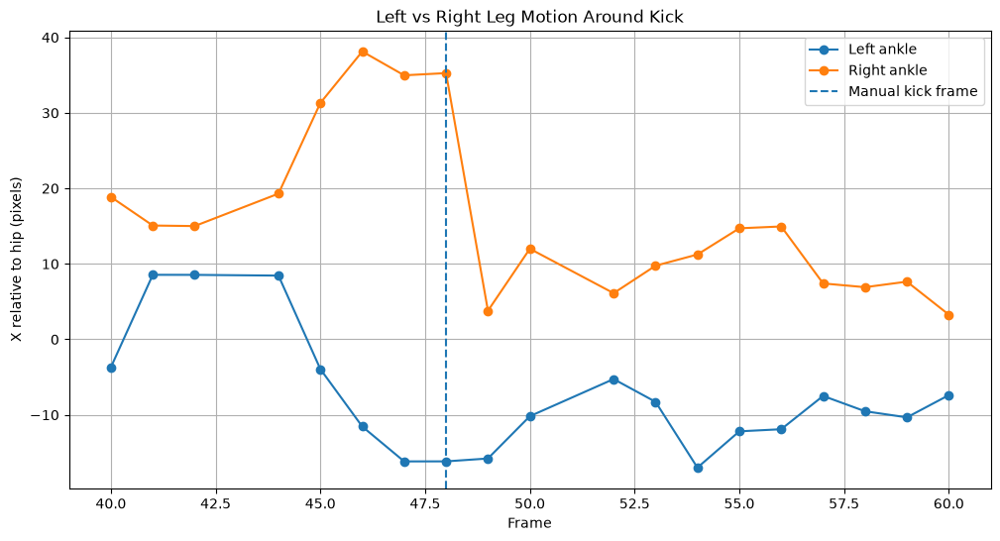

In [38]:
frames_rel = np.array([
    d["frame"] for d in relative_data
])

left_x = np.array([
    d["left_x"] for d in relative_data
])

right_x = np.array([
    d["right_x"] for d in relative_data
])

plt.figure(figsize=(12, 6))

plt.plot(
    frames_rel,
    left_x,
    "o-",
    label="Left ankle"
)

plt.plot(
    frames_rel,
    right_x,
    "o-",
    label="Right ankle"
)

# 我们人工观察的触球附近
plt.axvline(
    48,
    linestyle="--",
    label="Manual kick frame"
)

plt.xlabel("Frame")
plt.ylabel("X relative to hip (pixels)")
plt.title("Left vs Right Leg Motion Around Kick")
plt.legend()
plt.grid()

plt.show()

In [39]:
# 找到每一帧对应的 relative X
frame_to_data = {
    d["frame"]: d
    for d in relative_data
}

# 我们目前人工标记的 kick frame
kick_frame = 48

# 使用 kick 前后窗口
window_start = kick_frame - 3
window_end = kick_frame + 3

left_motion = 0.0
right_motion = 0.0

used_pairs = []

for fid in range(window_start, window_end):

    # 必须保证连续两帧都存在
    if fid not in frame_to_data:
        continue

    if fid + 1 not in frame_to_data:
        continue

    current = frame_to_data[fid]
    nxt = frame_to_data[fid + 1]

    left_change = abs(
        nxt["left_x"] - current["left_x"]
    )

    right_change = abs(
        nxt["right_x"] - current["right_x"]
    )

    left_motion += left_change
    right_motion += right_change

    used_pairs.append((fid, fid + 1))

print("Used frame pairs:", used_pairs)
print(f"Left leg motion : {left_motion:.2f}")
print(f"Right leg motion: {right_motion:.2f}")

Used frame pairs: [(45, 46), (46, 47), (47, 48), (48, 49), (49, 50)]
Left leg motion : 18.21
Right leg motion: 49.95


In [40]:
if right_motion > left_motion:
    kicking_foot = "RIGHT"
else:
    kicking_foot = "LEFT"

print()
print("Predicted kicking foot:", kicking_foot)


Predicted kicking foot: RIGHT


In [41]:
left_changes = []
right_changes = []

for fid in range(window_start, window_end):

    if fid not in frame_to_data:
        continue

    if fid + 1 not in frame_to_data:
        continue

    current = frame_to_data[fid]
    nxt = frame_to_data[fid + 1]

    left_changes.append(
        abs(nxt["left_x"] - current["left_x"])
    )

    right_changes.append(
        abs(nxt["right_x"] - current["right_x"])
    )

print(
    "Left max movement :",
    round(max(left_changes), 2)
)

print(
    "Right max movement:",
    round(max(right_changes), 2)
)

Left max movement : 7.61
Right max movement: 31.47


In [46]:
import importlib
import src.kicker_analysis

importlib.reload(src.kicker_analysis)

from src.kicker_analysis import KickerFeatureExtractor

In [43]:
import sys

print(sys.executable)

C:\Users\30605\PycharmProjects\JupyterProject\.venv\Scripts\python.exe


In [44]:
%pip install scipy

  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Note: you may need to restart the kernel to use updated packages.


In [45]:
import scipy

print("SciPy version:", scipy.__version__)

SciPy version: 1.18.1


In [47]:
extractor = KickerFeatureExtractor()

In [48]:
frames = []

left_ankle_x = []
right_ankle_x = []

left_hip_x = []
right_hip_x = []

for fid in sorted(tracked.keys()):

    kp = tracked[fid]["keypoints"]

    if (
        np.allclose(kp[11], 0)
        or np.allclose(kp[12], 0)
        or np.allclose(kp[15], 0)
        or np.allclose(kp[16], 0)
    ):
        continue

    frames.append(fid)

    left_hip_x.append(kp[11][0])
    right_hip_x.append(kp[12][0])

    left_ankle_x.append(kp[15][0])
    right_ankle_x.append(kp[16][0])

In [ ]:
result = extractor.classify_kicking_foot_from_motion(
    frames=frames,
    left_ankles=[tracked[fid]["keypoints"][15] for fid in frames],
    right_ankles=[tracked[fid]["keypoints"][16] for fid in frames],
    left_hips=[tracked[fid]["keypoints"][11] for fid in frames],
    right_hips=[tracked[fid]["keypoints"][12] for fid in frames],
    kick_frame=48,
    window=3,
)

result


In [53]:
#第二个人##################################################################################
for i, video in enumerate(videos):
    if "kane" in video.name.lower():
        print(i, video.name)

1 col_eng_p02_kane.mp4
2 col_eng_p02_kane_eng9.mp4


In [55]:
video_path = str(
    clips_dir / "col_eng_p02_kane_eng9.mp4"
)

print("Kane penalty video:", video_path)

Kane penalty video: data\raw_clips\col_eng_p02_kane_eng9.mp4


In [56]:
from pathlib import Path

print("Exists:", Path(video_path).exists())

Exists: True


In [57]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = frame_count / fps

cap.release()

print("FPS:", fps)
print("Frames:", frame_count)
print("Duration:", round(duration, 2), "seconds")

FPS: 30.0
Frames: 390
Duration: 13.0 seconds


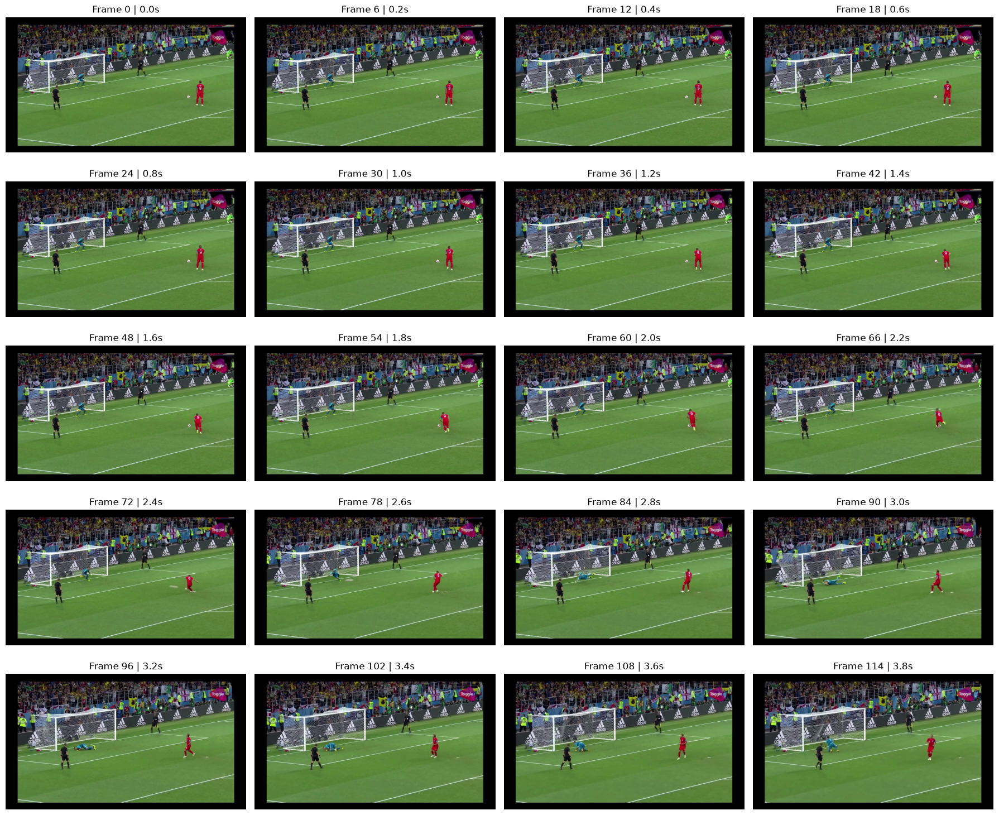

In [58]:
cap = cv2.VideoCapture(video_path)

sample_times = np.arange(
    0,
    min(4.0, duration),
    0.2
)

cols = 4
rows = int(np.ceil(len(sample_times) / cols))

plt.figure(figsize=(18, rows * 3))

for i, t in enumerate(sample_times):

    fid = int(t * fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    plt.subplot(rows, cols, i + 1)

    plt.imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )

    plt.title(f"Frame {fid} | {t:.1f}s")
    plt.axis("off")

cap.release()

plt.tight_layout()
plt.show()

In [59]:
manual_kick_frame = 72
anchor_frame = manual_kick_frame

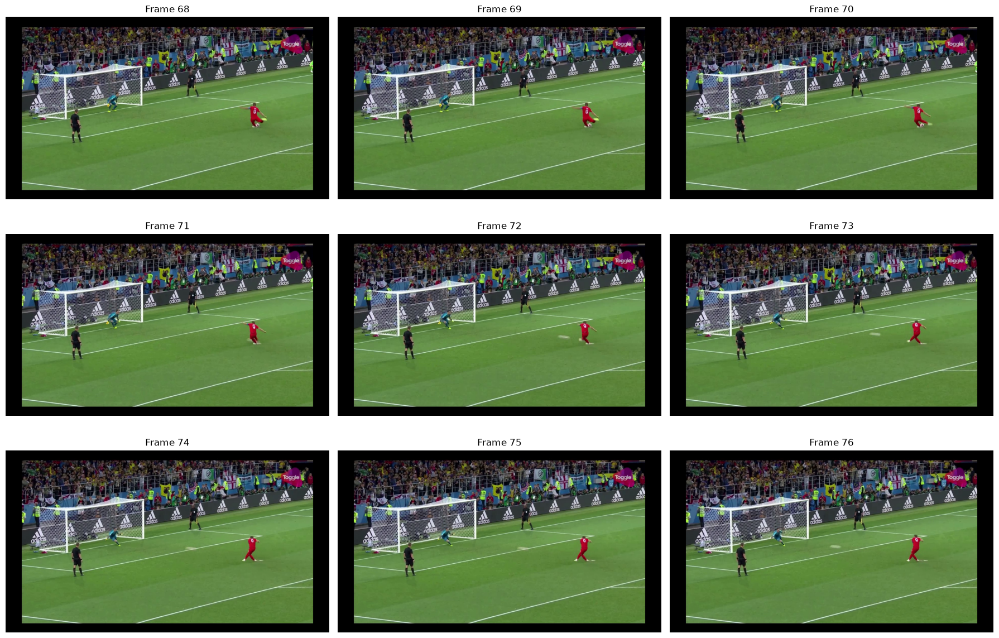

In [60]:
fine_frames = range(
    manual_kick_frame - 4,
    manual_kick_frame + 5
)

cap = cv2.VideoCapture(video_path)

plt.figure(figsize=(18, 12))

for i, fid in enumerate(fine_frames):
    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    plt.subplot(3, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Frame {fid}")
    plt.axis("off")

cap.release()

plt.tight_layout()
plt.show()

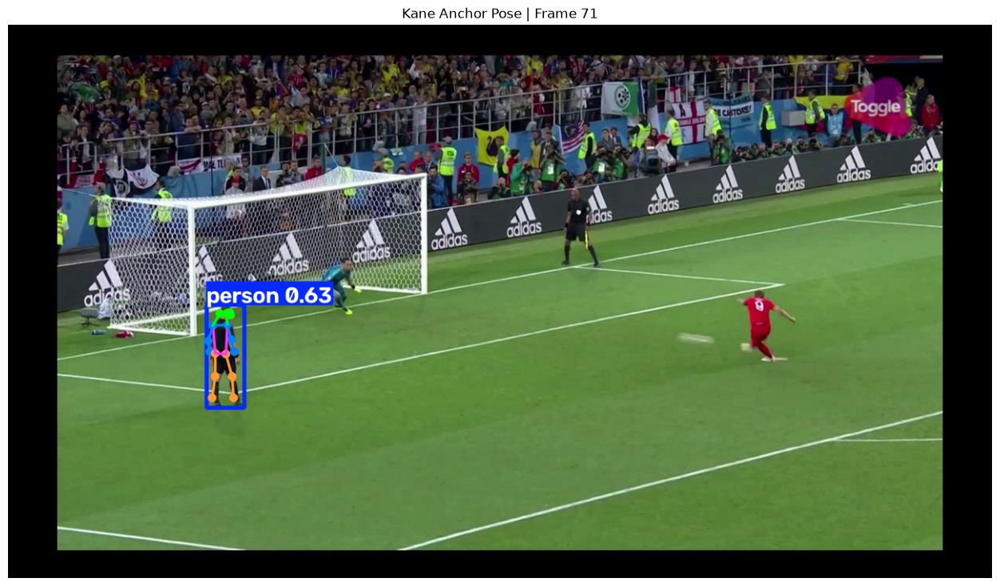

In [61]:
cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, anchor_frame)

ret, anchor_img = cap.read()
cap.release()

anchor_result = pose_model(
    anchor_img,
    conf=0.25,
    verbose=False
)[0]

annotated = anchor_result.plot()

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("Kane Anchor Pose | Frame 71")
plt.axis("off")
plt.show()

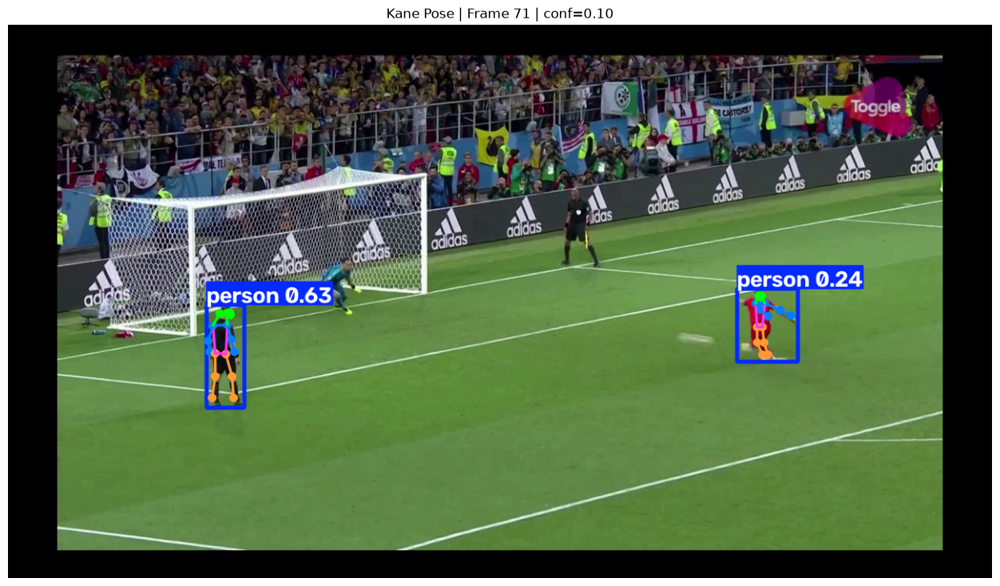

Detected persons: 2


In [63]:
anchor_result = pose_model(
    anchor_img,
    conf=0.10,
    verbose=False
)[0]

annotated = anchor_result.plot()

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("Kane Pose | Frame 71 | conf=0.10")
plt.axis("off")
plt.show()

print("Detected persons:", len(anchor_result.boxes))

In [64]:
anchor_boxes = anchor_result.boxes.xyxy.cpu().numpy()

for i, box in enumerate(anchor_boxes):
    x1, y1, x2, y2 = box

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    print(
        f"Person {i}: "
        f"center=({cx:.1f}, {cy:.1f})"
    )

Person 0: center=(283.0, 431.6)
Person 1: center=(987.8, 390.9)


In [65]:
centers_x = (
    anchor_boxes[:, 0] + anchor_boxes[:, 2]
) / 2

anchor_idx = int(np.argmax(centers_x))

print("Kane = Person", anchor_idx)

Kane = Person 1


In [66]:
x1, y1, x2, y2 = anchor_boxes[anchor_idx]

anchor_center = np.array([
    (x1 + x2) / 2,
    (y1 + y2) / 2
])

print("Kane Person:", anchor_idx)
print("Kane center:", anchor_center)

Kane Person: 1
Kane center: [     987.78      390.92]


In [67]:
track_start = manual_kick_frame - 8
track_end = manual_kick_frame + 12

print("Tracking range:", track_start, "→", track_end)

Tracking range: 64 → 84


In [68]:
tracked = {}

In [69]:
previous_center = anchor_center.copy()

cap = cv2.VideoCapture(video_path)

for fid in range(anchor_frame, track_end + 1):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    result_pose = pose_model(
        img,
        conf=0.10,
        verbose=False
    )[0]

    if result_pose.boxes is None or len(result_pose.boxes) == 0:
        print(f"Frame {fid}: no person")
        continue

    boxes = result_pose.boxes.xyxy.cpu().numpy()
    keypoints = result_pose.keypoints.xy.cpu().numpy()

    idx, center, distance = find_closest_person(
        boxes,
        previous_center,
        max_move=80
    )

    if idx is None:
        print(
            f"Frame {fid}: Kane missing "
            f"(nearest={distance:.1f}px)"
        )
        continue

    tracked[fid] = {
        "box": boxes[idx],
        "keypoints": keypoints[idx],
        "center": center
    }

    previous_center = center

    print(
        f"Frame {fid}: "
        f"person={idx}, "
        f"center=({center[0]:.1f}, {center[1]:.1f}), "
        f"move={distance:.1f}px"
    )

cap.release()

Frame 72: person=1, center=(987.8, 390.9), move=0.0px
Frame 73: person=1, center=(977.6, 389.0), move=10.3px
Frame 74: person=0, center=(972.9, 388.7), move=4.7px
Frame 75: person=0, center=(972.9, 388.7), move=0.1px
Frame 76: person=1, center=(973.4, 385.3), move=3.5px
Frame 77: person=0, center=(977.0, 382.1), move=4.8px
Frame 78: person=0, center=(978.5, 381.0), move=1.8px
Frame 79: person=1, center=(976.8, 379.5), move=2.3px
Frame 80: person=1, center=(974.7, 377.5), move=2.9px
Frame 81: person=1, center=(974.6, 377.4), move=0.1px
Frame 82: person=1, center=(974.1, 374.7), move=2.8px
Frame 83: person=1, center=(972.7, 374.0), move=1.6px
Frame 84: person=1, center=(969.5, 374.6), move=3.3px


In [70]:
previous_center = anchor_center.copy()

cap = cv2.VideoCapture(video_path)

for fid in range(anchor_frame - 1, track_start - 1, -1):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    result_pose = pose_model(
        img,
        conf=0.10,
        verbose=False
    )[0]

    if result_pose.boxes is None or len(result_pose.boxes) == 0:
        print(f"Frame {fid}: no person")
        continue

    boxes = result_pose.boxes.xyxy.cpu().numpy()
    keypoints = result_pose.keypoints.xy.cpu().numpy()

    idx, center, distance = find_closest_person(
        boxes,
        previous_center,
        max_move=80
    )

    if idx is None:
        print(
            f"Frame {fid}: Kane missing "
            f"(nearest={distance:.1f}px)"
        )
        continue

    tracked[fid] = {
        "box": boxes[idx],
        "keypoints": keypoints[idx],
        "center": center
    }

    previous_center = center

    print(
        f"Frame {fid}: "
        f"person={idx}, "
        f"center=({center[0]:.1f}, {center[1]:.1f}), "
        f"move={distance:.1f}px"
    )

cap.release()

print()
print(
    f"成功 tracking: {len(tracked)} / "
    f"{track_end - track_start + 1} frames"
)

Frame 71: person=1, center=(982.4, 391.1), move=5.4px
Frame 70: person=1, center=(979.7, 388.8), move=3.6px
Frame 69: person=1, center=(988.5, 387.6), move=8.9px
Frame 68: person=1, center=(991.4, 387.5), move=2.9px
Frame 67: person=1, center=(996.4, 385.4), move=5.5px
Frame 66: person=1, center=(993.3, 384.3), move=3.3px
Frame 65: person=1, center=(997.2, 385.6), move=4.1px
Frame 64: person=1, center=(998.2, 387.6), move=2.2px

成功 tracking: 21 / 21 frames


In [71]:
frames = []
left_ankle_x = []
right_ankle_x = []
left_hip_x = []
right_hip_x = []

for fid in sorted(tracked.keys()):

    kp = tracked[fid]["keypoints"]

    if (
        np.allclose(kp[11], 0)
        or np.allclose(kp[12], 0)
        or np.allclose(kp[15], 0)
        or np.allclose(kp[16], 0)
    ):
        print(f"Frame {fid}: invalid keypoints")
        continue

    frames.append(fid)

    left_hip_x.append(kp[11][0])
    right_hip_x.append(kp[12][0])

    left_ankle_x.append(kp[15][0])
    right_ankle_x.append(kp[16][0])

print("有效 Pose frames:", len(frames))
print("Frames:", frames)

有效 Pose frames: 21
Frames: [64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84]


In [ ]:
kane_result = extractor.classify_kicking_foot_from_motion(
    frames=frames,
    left_ankles=[tracked[fid]["keypoints"][15] for fid in frames],
    right_ankles=[tracked[fid]["keypoints"][16] for fid in frames],
    left_hips=[tracked[fid]["keypoints"][11] for fid in frames],
    right_hips=[tracked[fid]["keypoints"][12] for fid in frames],
    kick_frame=71,
    window=3,
)

kane_result


In [73]:
#左脚将测试
video_path = str(
    clips_dir / "cro_den_p08_pivaric_cro22.mp4"
)

print("Pivaric video:", video_path)
print("Exists:", Path(video_path).exists())

Pivaric video: data\raw_clips\cro_den_p08_pivaric_cro22.mp4
Exists: True


In [74]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = frame_count / fps

cap.release()

print("FPS:", fps)
print("Frames:", frame_count)
print("Duration:", round(duration, 2), "seconds")

FPS: 30.0
Frames: 690
Duration: 23.0 seconds


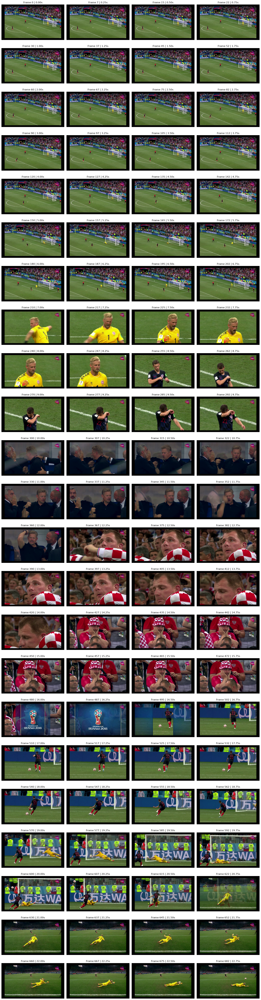

In [76]:
cap = cv2.VideoCapture(video_path)

# 整个视频每 0.25 秒取一帧
sample_times = np.arange(
    0,
    duration,
    0.25
)

cols = 4
rows = int(np.ceil(len(sample_times) / cols))

plt.figure(figsize=(18, rows * 3))

for i, t in enumerate(sample_times):

    fid = int(t * fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    plt.subplot(rows, cols, i + 1)

    plt.imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )

    plt.title(
        f"Frame {fid} | {t:.2f}s"
    )

    plt.axis("off")

cap.release()

plt.tight_layout()
plt.show()

In [78]:
# 查看原图尺寸
h, w = anchor_img.shape[:2]
print("Image size:", w, "x", h)

Image size: 1280 x 720


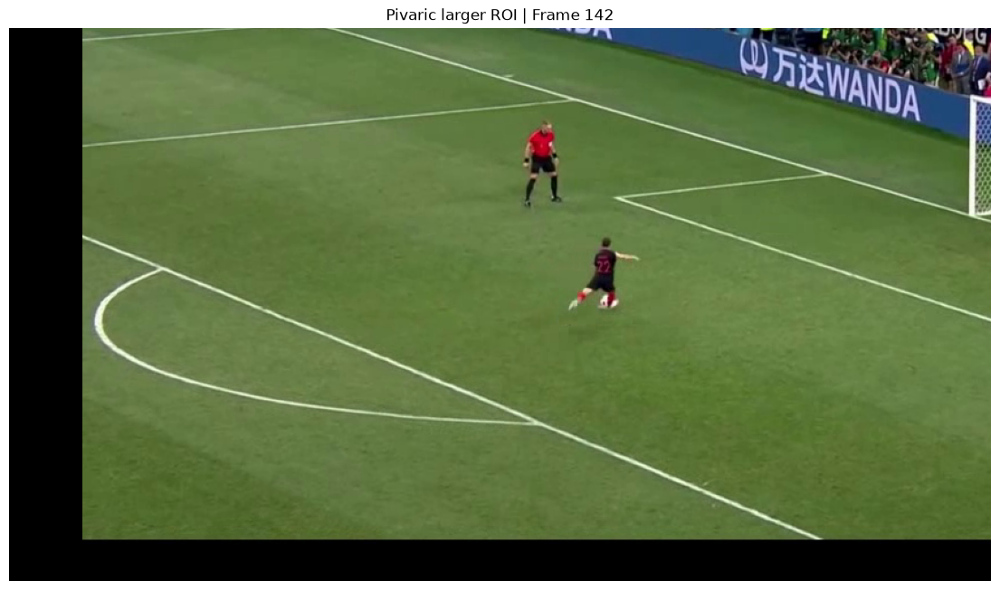

In [83]:
fid = 142

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, fid)

ret, img = cap.read()
cap.release()

h, w = img.shape[:2]

# 左侧约 2/3 宽度
# 下侧约 2/3 高度
x1 = 0
x2 = int(w * 0.67)

y1 = int(h * 0.33)
y2 = h

roi = img[y1:y2, x1:x2]

plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("Pivaric larger ROI | Frame 142")
plt.axis("off")
plt.show()

In [84]:
manual_kick_frame = 142
anchor_frame = manual_kick_frame

track_start = manual_kick_frame - 8
track_end = manual_kick_frame + 12

print("Kick frame:", manual_kick_frame)
print("Tracking range:", track_start, "->", track_end)

Kick frame: 142
Tracking range: 134 -> 154


In [85]:
def get_pivaric_roi(frame, scale=2.0):
    """
    Crop the left-bottom 2/3 region and enlarge it.

    The same ROI must be used for every frame so that
    pose coordinates remain comparable over time.
    """

    h, w = frame.shape[:2]

    x1 = 0
    x2 = int(w * 0.67)

    y1 = int(h * 0.33)
    y2 = h

    roi = frame[y1:y2, x1:x2]

    roi_large = cv2.resize(
        roi,
        None,
        fx=scale,
        fy=scale,
        interpolation=cv2.INTER_CUBIC
    )

    return roi_large

In [86]:
cap = cv2.VideoCapture(video_path)

cap.set(
    cv2.CAP_PROP_POS_FRAMES,
    anchor_frame
)

ret, anchor_img = cap.read()

cap.release()

if not ret:
    raise RuntimeError("无法读取 Frame 142")

anchor_roi = get_pivaric_roi(anchor_img)

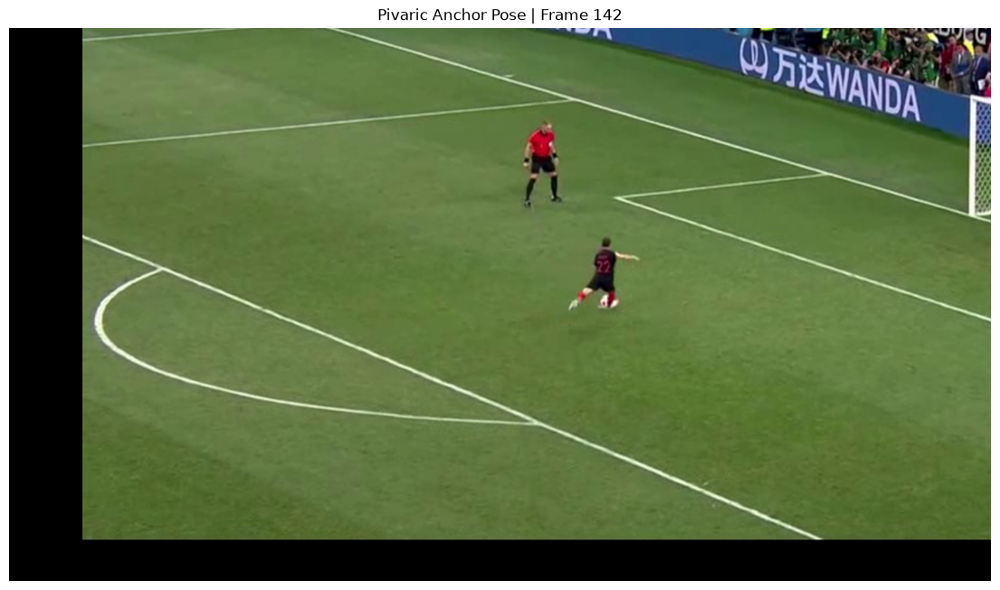

Detected persons: 0


In [87]:
anchor_result = pose_model(
    anchor_roi,
    conf=0.10,
    verbose=False
)[0]

annotated = anchor_result.plot()

plt.figure(figsize=(14, 9))

plt.imshow(
    cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    f"Pivaric Anchor Pose | Frame {anchor_frame}"
)

plt.axis("off")
plt.show()

print(
    "Detected persons:",
    len(anchor_result.boxes)
)

In [88]:
from ultralytics import YOLO

pose_model_m = YOLO(str(PROJECT_ROOT / "models" / "weights" / "yolo11m_pose.pt"))

print("YOLO11m-pose loaded")

YOLO11m-pose loaded


In [89]:
anchor_roi

array([[[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [14,  1,  0],
        [22,  6,  3],
        [27,  8,  5]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [15,  1,  1],
        [21,  4,  2],
        [25,  6,  3]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [17,  1,  1],
        [20,  2,  1],
        [22,  3,  1]],

       ...,

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0]]], shape=(966, 1714, 3), dtype=uint8)

Detected persons: 2


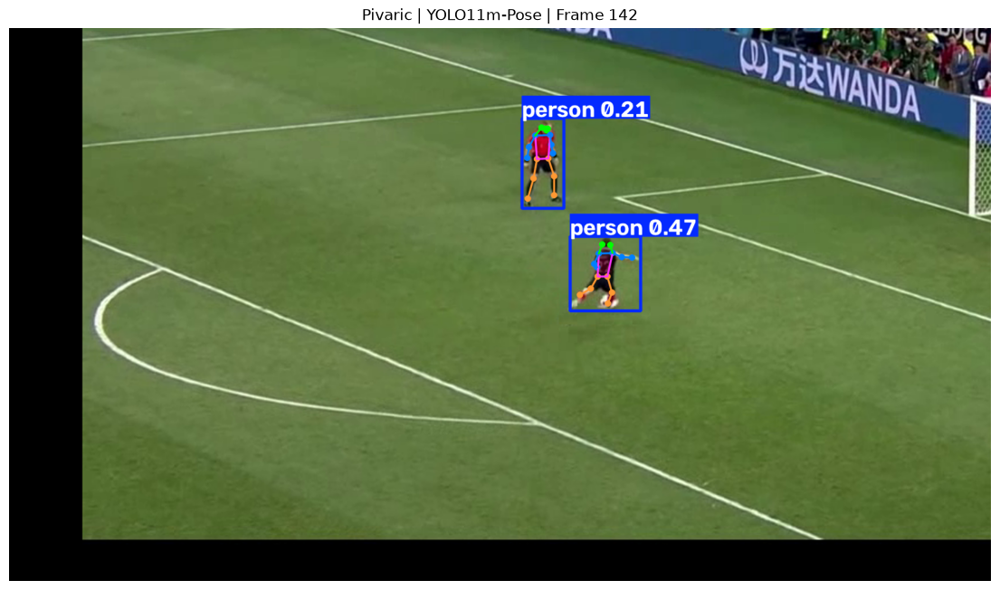

In [90]:
result_m = pose_model_m(
    anchor_roi,
    conf=0.10,
    imgsz=1280,
    verbose=False
)[0]

print("Detected persons:", len(result_m.boxes))

annotated_m = result_m.plot()

plt.figure(figsize=(14, 9))

plt.imshow(
    cv2.cvtColor(
        annotated_m,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "Pivaric | YOLO11m-Pose | Frame 142"
)

plt.axis("off")
plt.show()

In [91]:
anchor_result = result_m

anchor_boxes = anchor_result.boxes.xyxy.cpu().numpy()
anchor_keypoints = anchor_result.keypoints.xy.cpu().numpy()

print("Detected persons:", len(anchor_boxes))

for i, box in enumerate(anchor_boxes):
    x1, y1, x2, y2 = box

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    print(
        f"Person {i}: "
        f"center=({cx:.1f}, {cy:.1f})"
    )

Detected persons: 2
Person 0: center=(1041.4, 429.2)
Person 1: center=(931.7, 237.1)


In [92]:
centers_y = (
    anchor_boxes[:, 1] +
    anchor_boxes[:, 3]
) / 2

anchor_idx = int(np.argmax(centers_y))

print("Pivaric = Person", anchor_idx)

Pivaric = Person 0


In [93]:
anchor_box = anchor_boxes[anchor_idx]

x1, y1, x2, y2 = anchor_box

anchor_center = np.array([
    (x1 + x2) / 2,
    (y1 + y2) / 2
])

anchor_frame = 142

print("Anchor frame:", anchor_frame)
print("Pivaric Person:", anchor_idx)
print("Anchor center:", anchor_center)

Anchor frame: 142
Pivaric Person: 0
Anchor center: [     1041.4      429.21]


In [94]:
manual_kick_frame = 142

track_start = 134
track_end = 154

tracked_pivaric = {}

# 先保存 Frame 142 的 Pivaric
tracked_pivaric[anchor_frame] = {
    "box": anchor_boxes[anchor_idx],
    "keypoints": anchor_keypoints[anchor_idx],
    "center": anchor_center
}

print("Anchor saved:", anchor_frame)

Anchor saved: 142


In [95]:
def find_closest_person(
    boxes,
    previous_center,
    max_move=120
):
    centers = np.column_stack([
        (boxes[:, 0] + boxes[:, 2]) / 2,
        (boxes[:, 1] + boxes[:, 3]) / 2
    ])

    distances = np.linalg.norm(
        centers - previous_center,
        axis=1
    )

    idx = int(np.argmin(distances))
    min_distance = float(distances[idx])

    if min_distance > max_move:
        return None, None, min_distance

    return idx, centers[idx], min_distance

In [ ]:
# The following Pivaric tracking cells explicitly pass this image size.
pivaric_imgsz = 1280
pose_model_m


In [98]:
previous_center = anchor_center.copy()

cap = cv2.VideoCapture(video_path)

for fid in range(143, 155):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        print(f"Frame {fid}: read failed")
        continue

    # 使用之前确定的大 ROI
    roi_large = get_pivaric_roi(img)

    result_pose = pose_model_m(
        roi_large,
        conf=0.10,
        imgsz=1280,
        verbose=False
    )[0]

    if (
        result_pose.boxes is None
        or len(result_pose.boxes) == 0
    ):
        print(f"Frame {fid}: Pivaric missing")
        continue

    boxes = result_pose.boxes.xyxy.cpu().numpy()
    keypoints = result_pose.keypoints.xy.cpu().numpy()

    idx, center, distance = find_closest_person(
        boxes,
        previous_center,
        max_move=120
    )

    if idx is None:
        print(
            f"Frame {fid}: Pivaric missing "
            f"(nearest={distance:.1f}px)"
        )
        continue

    tracked_pivaric[fid] = {
        "box": boxes[idx],
        "keypoints": keypoints[idx],
        "center": center
    }

    previous_center = center

    print(
        f"Frame {fid}: "
        f"person={idx}, "
        f"center=({center[0]:.1f}, {center[1]:.1f}), "
        f"move={distance:.1f}px"
    )

cap.release()

Frame 143: person=0, center=(1042.1, 430.7), move=1.6px
Frame 144: person=0, center=(1044.6, 430.3), move=2.5px
Frame 145: person=0, center=(1050.7, 433.7), move=7.0px
Frame 146: person=0, center=(1042.2, 435.3), move=8.6px
Frame 147: person=0, center=(1041.8, 436.4), move=1.2px
Frame 148: person=0, center=(1041.6, 437.2), move=0.8px
Frame 149: person=0, center=(1042.9, 436.5), move=1.5px
Frame 150: person=0, center=(1042.7, 436.5), move=0.2px
Frame 151: person=0, center=(1045.2, 436.7), move=2.6px
Frame 152: person=0, center=(1047.8, 433.7), move=4.0px
Frame 153: person=1, center=(1045.7, 435.1), move=2.5px
Frame 154: person=0, center=(1046.8, 436.0), move=1.4px


In [99]:
previous_center = anchor_center.copy()

cap = cv2.VideoCapture(video_path)

for fid in range(141, 133, -1):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        print(f"Frame {fid}: read failed")
        continue

    # 使用完全相同的大 ROI
    roi_large = get_pivaric_roi(img)

    # 使用 YOLO11m-Pose
    result_pose = pose_model_m(
        roi_large,
        conf=0.10,
        imgsz=1280,
        verbose=False
    )[0]

    if (
        result_pose.boxes is None
        or len(result_pose.boxes) == 0
    ):
        print(f"Frame {fid}: Pivaric missing")
        continue

    boxes = result_pose.boxes.xyxy.cpu().numpy()
    keypoints = result_pose.keypoints.xy.cpu().numpy()

    idx, center, distance = find_closest_person(
        boxes,
        previous_center,
        max_move=120
    )

    if idx is None:
        print(
            f"Frame {fid}: Pivaric missing "
            f"(nearest={distance:.1f}px)"
        )
        continue

    tracked_pivaric[fid] = {
        "box": boxes[idx],
        "keypoints": keypoints[idx],
        "center": center
    }

    previous_center = center

    print(
        f"Frame {fid}: "
        f"person={idx}, "
        f"center=({center[0]:.1f}, {center[1]:.1f}), "
        f"move={distance:.1f}px"
    )

cap.release()

Frame 141: person=0, center=(1036.3, 437.7), move=10.0px
Frame 140: person=0, center=(1030.8, 443.6), move=8.1px
Frame 139: person=0, center=(1022.4, 445.4), move=8.5px
Frame 138: person=0, center=(1004.3, 446.9), move=18.2px
Frame 137: person=0, center=(1004.5, 447.0), move=0.2px
Frame 136: person=0, center=(995.1, 447.4), move=9.4px
Frame 135: person=0, center=(982.9, 457.9), move=16.1px
Frame 134: person=0, center=(976.0, 464.5), move=9.5px


In [100]:
missing_frames = [
    fid
    for fid in range(134, 155)
    if fid not in tracked_pivaric
]

print()
print(
    f"成功 tracking: "
    f"{len(tracked_pivaric)} / 21"
)

print("Missing frames:", missing_frames)


成功 tracking: 21 / 21
Missing frames: []


In [101]:
frames = []

left_ankle_x = []
right_ankle_x = []

left_hip_x = []
right_hip_x = []

invalid_frames = []

for fid in sorted(tracked_pivaric.keys()):

    kp = tracked_pivaric[fid]["keypoints"]

    # COCO Pose:
    # 11 = left hip
    # 12 = right hip
    # 15 = left ankle
    # 16 = right ankle

    if (
        np.allclose(kp[11], 0)
        or np.allclose(kp[12], 0)
        or np.allclose(kp[15], 0)
        or np.allclose(kp[16], 0)
    ):
        invalid_frames.append(fid)
        continue

    frames.append(fid)

    left_hip_x.append(kp[11][0])
    right_hip_x.append(kp[12][0])

    left_ankle_x.append(kp[15][0])
    right_ankle_x.append(kp[16][0])

print("有效 Pose frames:", len(frames))
print("Invalid frames:", invalid_frames)

有效 Pose frames: 21
Invalid frames: []


In [ ]:
pivaric_result = extractor.classify_kicking_foot_from_motion(
    frames=frames,
    left_ankles=[tracked_pivaric[fid]["keypoints"][15] for fid in frames],
    right_ankles=[tracked_pivaric[fid]["keypoints"][16] for fid in frames],
    left_hips=[tracked_pivaric[fid]["keypoints"][11] for fid in frames],
    right_hips=[tracked_pivaric[fid]["keypoints"][12] for fid in frames],
    kick_frame=142,
    window=3,
)

pivaric_result


In [103]:
frames_plot = []
left_rel_x = []
left_rel_y = []
right_rel_x = []
right_rel_y = []

for fid in sorted(tracked_pivaric.keys()):

    if fid < 139 or fid > 145:
        continue

    kp = tracked_pivaric[fid]["keypoints"]

    left_hip = kp[11]
    right_hip = kp[12]

    left_ankle = kp[15]
    right_ankle = kp[16]

    if (
        np.allclose(left_hip, 0)
        or np.allclose(right_hip, 0)
        or np.allclose(left_ankle, 0)
        or np.allclose(right_ankle, 0)
    ):
        continue

    hip_center = (
        left_hip + right_hip
    ) / 2

    left_relative = (
        left_ankle - hip_center
    )

    right_relative = (
        right_ankle - hip_center
    )

    frames_plot.append(fid)

    left_rel_x.append(left_relative[0])
    left_rel_y.append(left_relative[1])

    right_rel_x.append(right_relative[0])
    right_rel_y.append(right_relative[1])

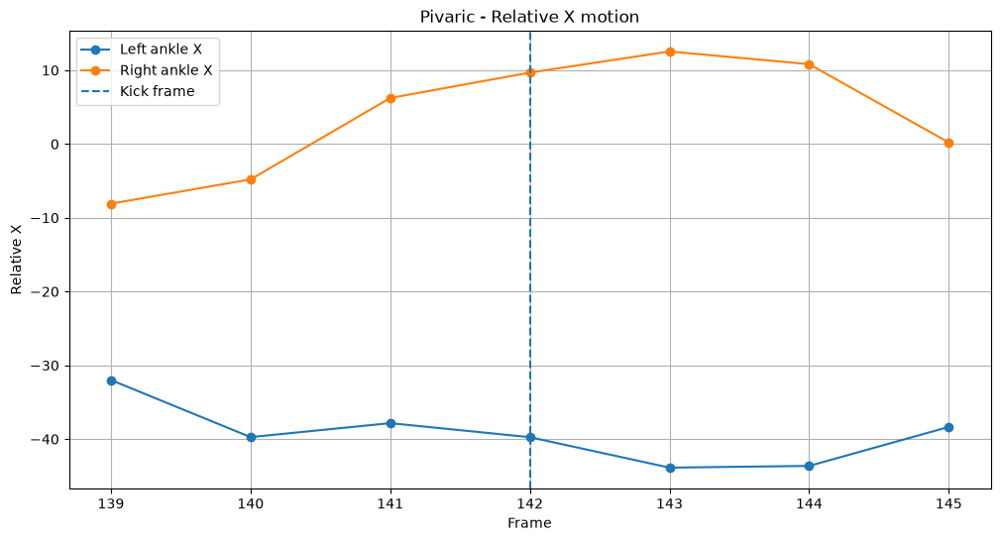

In [104]:
plt.figure(figsize=(12, 6))

plt.plot(
    frames_plot,
    left_rel_x,
    "o-",
    label="Left ankle X"
)

plt.plot(
    frames_plot,
    right_rel_x,
    "o-",
    label="Right ankle X"
)

plt.axvline(
    142,
    linestyle="--",
    label="Kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Relative X")
plt.title("Pivaric - Relative X motion")
plt.legend()
plt.grid()

plt.show()

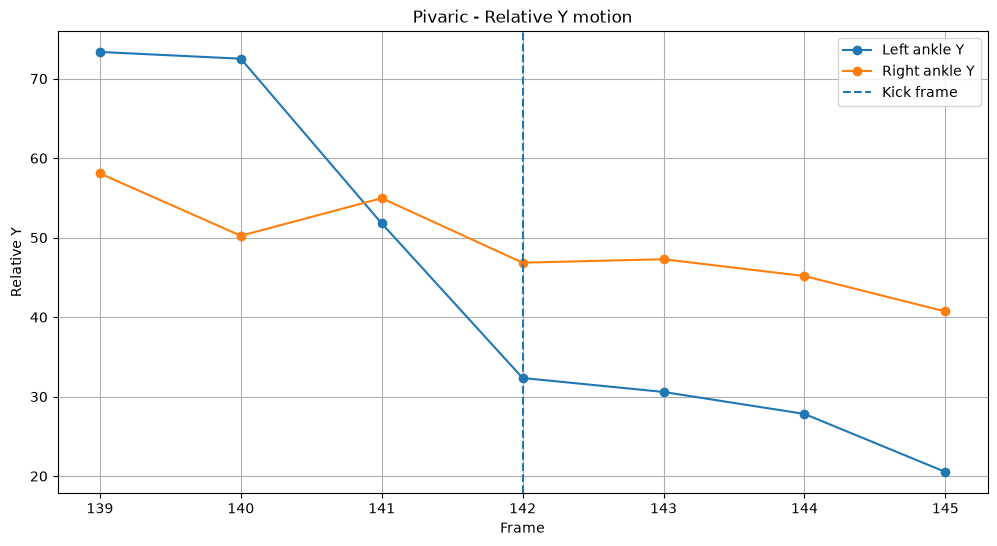

In [105]:
plt.figure(figsize=(12, 6))

plt.plot(
    frames_plot,
    left_rel_y,
    "o-",
    label="Left ankle Y"
)

plt.plot(
    frames_plot,
    right_rel_y,
    "o-",
    label="Right ankle Y"
)

plt.axvline(
    142,
    linestyle="--",
    label="Kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Relative Y")
plt.title("Pivaric - Relative Y motion")
plt.legend()
plt.grid()

plt.show()

In [106]:
left_motion_2d = []
right_motion_2d = []
motion_frames = []

for i in range(len(frames_plot) - 1):

    if frames_plot[i + 1] - frames_plot[i] != 1:
        continue

    left_dx = left_rel_x[i + 1] - left_rel_x[i]
    left_dy = left_rel_y[i + 1] - left_rel_y[i]

    right_dx = right_rel_x[i + 1] - right_rel_x[i]
    right_dy = right_rel_y[i + 1] - right_rel_y[i]

    left_move = np.hypot(left_dx, left_dy)
    right_move = np.hypot(right_dx, right_dy)

    left_motion_2d.append(left_move)
    right_motion_2d.append(right_move)

    motion_frames.append(frames_plot[i + 1])

print("LEFT 2D max  :", round(max(left_motion_2d), 2))
print("RIGHT 2D max :", round(max(right_motion_2d), 2))

print("LEFT 2D total :", round(sum(left_motion_2d), 2))
print("RIGHT 2D total:", round(sum(right_motion_2d), 2))

LEFT 2D max  : 20.81
RIGHT 2D max : 12.0
LEFT 2D total : 64.4
RIGHT 2D total: 46.46


In [107]:
frames_kane = []

left_rel_kane = []
right_rel_kane = []

for fid in sorted(tracked.keys()):

    # 只看 kick ±3
    if fid < 68 or fid > 74:
        continue

    kp = tracked[fid]["keypoints"]

    left_hip = kp[11]
    right_hip = kp[12]

    left_ankle = kp[15]
    right_ankle = kp[16]

    if (
        np.allclose(left_hip, 0)
        or np.allclose(right_hip, 0)
        or np.allclose(left_ankle, 0)
        or np.allclose(right_ankle, 0)
    ):
        continue

    hip_center = (
        left_hip + right_hip
    ) / 2

    frames_kane.append(fid)

    left_rel_kane.append(
        left_ankle - hip_center
    )

    right_rel_kane.append(
        right_ankle - hip_center
    )

left_rel_kane = np.array(left_rel_kane)
right_rel_kane = np.array(right_rel_kane)

In [108]:
left_2d = []
right_2d = []

for i in range(len(frames_kane) - 1):

    if frames_kane[i + 1] - frames_kane[i] != 1:
        continue

    left_move = np.linalg.norm(
        left_rel_kane[i + 1]
        - left_rel_kane[i]
    )

    right_move = np.linalg.norm(
        right_rel_kane[i + 1]
        - right_rel_kane[i]
    )

    left_2d.append(left_move)
    right_2d.append(right_move)

print("KANE")
print("LEFT 2D max  :", round(max(left_2d), 2))
print("RIGHT 2D max :", round(max(right_2d), 2))
print("LEFT 2D total :", round(sum(left_2d), 2))
print("RIGHT 2D total:", round(sum(right_2d), 2))

prediction = (
    "RIGHT"
    if max(right_2d) > max(left_2d)
    else "LEFT"
)

print("Prediction:", prediction)

KANE
LEFT 2D max  : 14.39
RIGHT 2D max : 20.75
LEFT 2D total : 49.43
RIGHT 2D total: 61.39
Prediction: RIGHT


In [110]:
kane_tracked = tracked.copy()

print("Kane tracked frames:", len(kane_tracked))

Kane tracked frames: 21


In [111]:
pivaric_tracked = tracked_pivaric.copy()

print("Pivaric tracked frames:", len(pivaric_tracked))

Pivaric tracked frames: 21


In [112]:
falcao_video_path = str(
    clips_dir / "col_eng_p01_falcao_col9.mp4"
)

falcao_kick_frame = 48

print(falcao_video_path)
print("Exists:", Path(falcao_video_path).exists())

data\raw_clips\col_eng_p01_falcao_col9.mp4
Exists: True


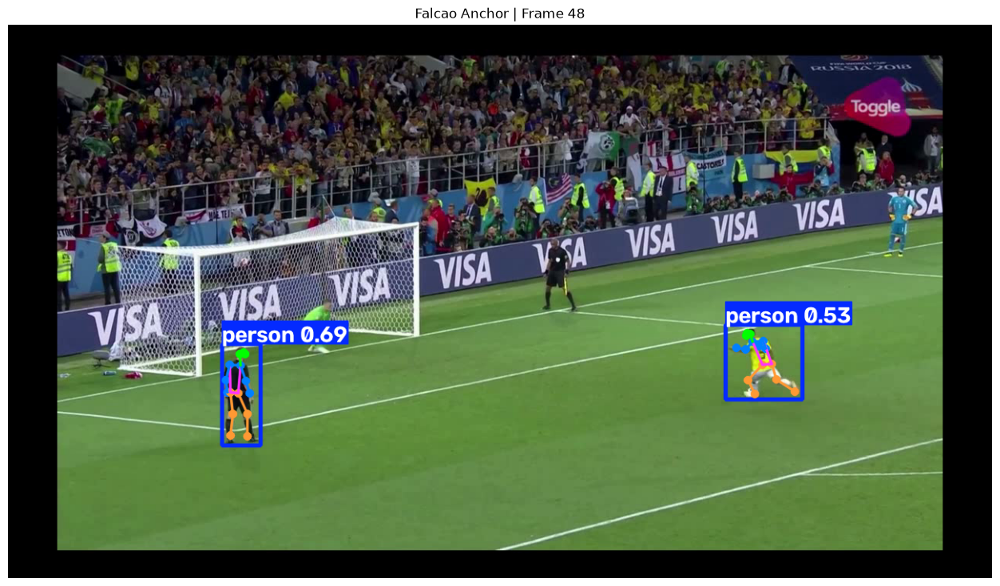

In [113]:
cap = cv2.VideoCapture(falcao_video_path)

cap.set(
    cv2.CAP_PROP_POS_FRAMES,
    falcao_kick_frame
)

ret, img = cap.read()
cap.release()

falcao_anchor_result = pose_model(
    img,
    conf=0.25,
    verbose=False
)[0]

annotated = falcao_anchor_result.plot()

plt.figure(figsize=(16, 9))
plt.imshow(
    cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Falcao Anchor | Frame 48")
plt.axis("off")
plt.show()

In [114]:
boxes = (
    falcao_anchor_result
    .boxes.xyxy
    .cpu()
    .numpy()
)

keypoints = (
    falcao_anchor_result
    .keypoints.xy
    .cpu()
    .numpy()
)

for i, box in enumerate(boxes):

    x1, y1, x2, y2 = box

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    print(
        f"Person {i}: "
        f"center=({cx:.1f}, {cy:.1f})"
    )

Person 0: center=(303.3, 481.6)
Person 1: center=(983.4, 439.3)


In [115]:
centers_x = (
    boxes[:, 0] + boxes[:, 2]
) / 2

falcao_anchor_idx = int(
    np.argmax(centers_x)
)

falcao_anchor_box = boxes[
    falcao_anchor_idx
]

x1, y1, x2, y2 = falcao_anchor_box

falcao_anchor_center = np.array([
    (x1 + x2) / 2,
    (y1 + y2) / 2
])

print(
    "Falcao Person:",
    falcao_anchor_idx
)

print(
    "Falcao center:",
    falcao_anchor_center
)

Falcao Person: 1
Falcao center: [     983.44      439.28]


In [116]:
falcao_track_start = 40
falcao_track_end = 60

falcao_tracked = {}

falcao_tracked[48] = {
    "box": boxes[falcao_anchor_idx],
    "keypoints": keypoints[falcao_anchor_idx],
    "center": falcao_anchor_center
}

In [117]:
previous_center = falcao_anchor_center.copy()

cap = cv2.VideoCapture(falcao_video_path)

for fid in range(49, 61):

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        fid
    )

    ret, img = cap.read()

    if not ret:
        continue

    result_pose = pose_model(
        img,
        conf=0.25,
        verbose=False
    )[0]

    if (
        result_pose.boxes is None
        or len(result_pose.boxes) == 0
    ):
        continue

    current_boxes = (
        result_pose.boxes.xyxy
        .cpu()
        .numpy()
    )

    current_keypoints = (
        result_pose.keypoints.xy
        .cpu()
        .numpy()
    )

    idx, center, distance = find_closest_person(
        current_boxes,
        previous_center,
        max_move=80
    )

    if idx is None:
        continue

    falcao_tracked[fid] = {
        "box": current_boxes[idx],
        "keypoints": current_keypoints[idx],
        "center": center
    }

    previous_center = center

cap.release()

In [118]:
previous_center = falcao_anchor_center.copy()

cap = cv2.VideoCapture(falcao_video_path)

for fid in range(47, 39, -1):

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        fid
    )

    ret, img = cap.read()

    if not ret:
        continue

    result_pose = pose_model(
        img,
        conf=0.25,
        verbose=False
    )[0]

    if (
        result_pose.boxes is None
        or len(result_pose.boxes) == 0
    ):
        continue

    current_boxes = (
        result_pose.boxes.xyxy
        .cpu()
        .numpy()
    )

    current_keypoints = (
        result_pose.keypoints.xy
        .cpu()
        .numpy()
    )

    idx, center, distance = find_closest_person(
        current_boxes,
        previous_center,
        max_move=80
    )

    if idx is None:
        continue

    falcao_tracked[fid] = {
        "box": current_boxes[idx],
        "keypoints": current_keypoints[idx],
        "center": center
    }

    previous_center = center

cap.release()

In [119]:
missing = [
    fid
    for fid in range(40, 61)
    if fid not in falcao_tracked
]

print(
    "Falcao tracked:",
    len(falcao_tracked),
    "/ 21"
)

print("Missing:", missing)

Falcao tracked: 19 / 21
Missing: [43, 51]


In [121]:
frames_falcao = []

left_rel_falcao = []
right_rel_falcao = []

for fid in sorted(
    falcao_tracked.keys()
):

    # kick ±3
    if fid < 45 or fid > 51:
        continue

    kp = falcao_tracked[fid]["keypoints"]

    left_hip = kp[11]
    right_hip = kp[12]

    left_ankle = kp[15]
    right_ankle = kp[16]

    if (
        np.allclose(left_hip, 0)
        or np.allclose(right_hip, 0)
        or np.allclose(left_ankle, 0)
        or np.allclose(right_ankle, 0)
    ):
        continue

    hip_center = (
        left_hip + right_hip
    ) / 2

    frames_falcao.append(fid)

    left_rel_falcao.append(
        left_ankle - hip_center
    )

    right_rel_falcao.append(
        right_ankle - hip_center
    )

left_rel_falcao = np.array(
    left_rel_falcao
)

right_rel_falcao = np.array(
    right_rel_falcao
)

In [122]:
left_2d = []
right_2d = []

for i in range(
    len(frames_falcao) - 1
):

    # missing frame 不跨过去计算
    if (
        frames_falcao[i + 1]
        - frames_falcao[i]
        != 1
    ):
        continue

    left_move = np.linalg.norm(
        left_rel_falcao[i + 1]
        - left_rel_falcao[i]
    )

    right_move = np.linalg.norm(
        right_rel_falcao[i + 1]
        - right_rel_falcao[i]
    )

    left_2d.append(left_move)
    right_2d.append(right_move)

print("FALCAO")

print(
    "LEFT 2D max  :",
    round(max(left_2d), 2)
)

print(
    "RIGHT 2D max :",
    round(max(right_2d), 2)
)

print(
    "LEFT 2D total :",
    round(sum(left_2d), 2)
)

print(
    "RIGHT 2D total:",
    round(sum(right_2d), 2)
)

prediction = (
    "RIGHT"
    if max(right_2d) > max(left_2d)
    else "LEFT"
)

print(
    "Prediction:",
    prediction
)

FALCAO
LEFT 2D max  : 9.46
RIGHT 2D max : 31.47
LEFT 2D total : 23.72
RIGHT 2D total: 54.08
Prediction: RIGHT


In [124]:
import importlib
import src.kicker_analysis

importlib.reload(src.kicker_analysis)

from src.kicker_analysis import KickerFeatureExtractor

extractor = KickerFeatureExtractor()

print("New 2D kicker classifier loaded.")

New 2D kicker classifier loaded.


In [125]:
frames = []
left_ankles = []
right_ankles = []
left_hips = []
right_hips = []

for fid in sorted(falcao_tracked.keys()):

    kp = falcao_tracked[fid]["keypoints"]

    if (
        np.allclose(kp[11], 0)
        or np.allclose(kp[12], 0)
        or np.allclose(kp[15], 0)
        or np.allclose(kp[16], 0)
    ):
        continue

    frames.append(fid)

    left_hips.append(kp[11])
    right_hips.append(kp[12])

    left_ankles.append(kp[15])
    right_ankles.append(kp[16])

In [126]:
result = extractor.classify_kicking_foot_from_motion(
    frames=frames,
    left_ankles=left_ankles,
    right_ankles=right_ankles,
    left_hips=left_hips,
    right_hips=right_hips,
    kick_frame=48,
    window=3
)

result

{'kicking_foot': 'right',
 'left_max_motion': 9.46,
 'right_max_motion': 31.47,
 'left_total_motion': 23.72,
 'right_total_motion': 54.08,
 'motion_ratio': 3.33,
 'used_frame_pairs': [(45, 46), (46, 47), (47, 48), (48, 49), (49, 50)]}

In [127]:
#自动检测
motion_records = []

frame_ids = sorted(falcao_tracked.keys())

for i in range(len(frame_ids) - 1):

    fid1 = frame_ids[i]
    fid2 = frame_ids[i + 1]

    # 不跨 missing frame
    if fid2 - fid1 != 1:
        continue

    kp1 = falcao_tracked[fid1]["keypoints"]
    kp2 = falcao_tracked[fid2]["keypoints"]

    # 需要 hip + ankle
    required = [11, 12, 15, 16]

    if any(
        np.allclose(kp1[j], 0) or np.allclose(kp2[j], 0)
        for j in required
    ):
        continue

    # Frame t
    hip1 = (kp1[11] + kp1[12]) / 2

    left1 = kp1[15] - hip1
    right1 = kp1[16] - hip1

    # Frame t+1
    hip2 = (kp2[11] + kp2[12]) / 2

    left2 = kp2[15] - hip2
    right2 = kp2[16] - hip2

    # 2D movement
    left_motion = np.linalg.norm(
        left2 - left1
    )

    right_motion = np.linalg.norm(
        right2 - right1
    )

    motion_records.append({
        "frame": fid2,
        "left_motion": left_motion,
        "right_motion": right_motion,
        "max_motion": max(
            left_motion,
            right_motion
        )
    })

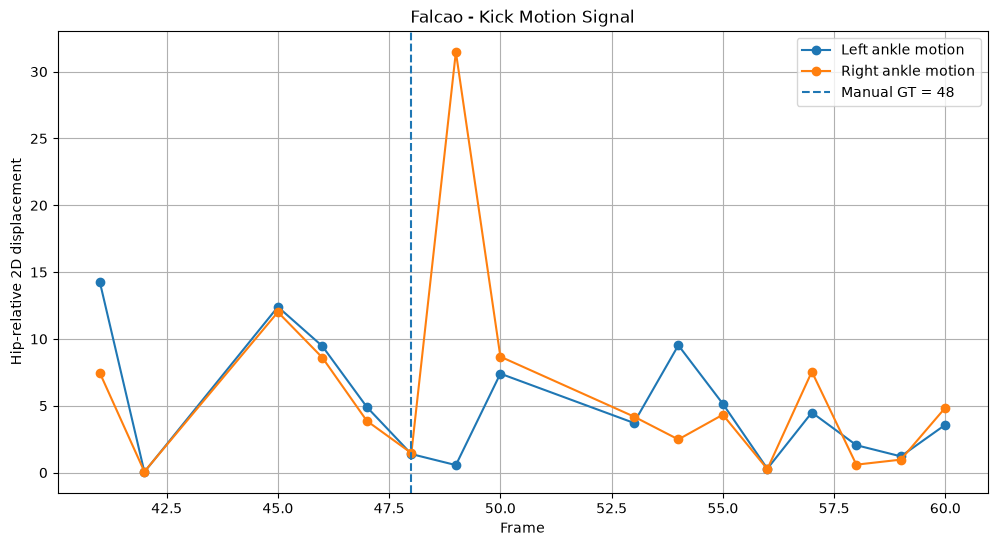

In [128]:
motion_frames = [
    r["frame"]
    for r in motion_records
]

left_motion = [
    r["left_motion"]
    for r in motion_records
]

right_motion = [
    r["right_motion"]
    for r in motion_records
]

plt.figure(figsize=(12, 6))

plt.plot(
    motion_frames,
    left_motion,
    "o-",
    label="Left ankle motion"
)

plt.plot(
    motion_frames,
    right_motion,
    "o-",
    label="Right ankle motion"
)

# 这里只用于验证，算法不知道48
plt.axvline(
    48,
    linestyle="--",
    label="Manual GT = 48"
)

plt.xlabel("Frame")
plt.ylabel("Hip-relative 2D displacement")
plt.title("Falcao - Kick Motion Signal")
plt.legend()
plt.grid()

plt.show()

In [129]:
best_record = max(
    motion_records,
    key=lambda r: r["max_motion"]
)

auto_kick_frame = best_record["frame"]

print(
    "Automatic kick candidate:",
    auto_kick_frame
)

print(
    "Manual ground truth:",
    48
)

print(
    "Frame error:",
    auto_kick_frame - 48
)

print(
    "Time error:",
    round(
        abs(auto_kick_frame - 48) / fps,
        3
    ),
    "seconds"
)

Automatic kick candidate: 49
Manual ground truth: 48
Frame error: 1
Time error: 0.033 seconds


In [130]:
motion_records_kane = []

frame_ids = sorted(kane_tracked.keys())

for i in range(len(frame_ids) - 1):

    fid1 = frame_ids[i]
    fid2 = frame_ids[i + 1]

    # 不跨 missing frame
    if fid2 - fid1 != 1:
        continue

    kp1 = kane_tracked[fid1]["keypoints"]
    kp2 = kane_tracked[fid2]["keypoints"]

    required = [11, 12, 15, 16]

    if any(
        np.allclose(kp1[j], 0) or
        np.allclose(kp2[j], 0)
        for j in required
    ):
        continue

    # Frame t
    hip1 = (kp1[11] + kp1[12]) / 2

    left1 = kp1[15] - hip1
    right1 = kp1[16] - hip1

    # Frame t+1
    hip2 = (kp2[11] + kp2[12]) / 2

    left2 = kp2[15] - hip2
    right2 = kp2[16] - hip2

    # 2D movement
    left_motion = np.linalg.norm(
        left2 - left1
    )

    right_motion = np.linalg.norm(
        right2 - right1
    )

    motion_records_kane.append({
        "frame": fid2,
        "left_motion": left_motion,
        "right_motion": right_motion,
        "max_motion": max(
            left_motion,
            right_motion
        )
    })

In [131]:
best_record_kane = max(
    motion_records_kane,
    key=lambda r: r["max_motion"]
)

auto_kick_kane = best_record_kane["frame"]

print(
    "Automatic kick candidate:",
    auto_kick_kane
)

print(
    "Manual ground truth:",
    71
)

print(
    "Frame error:",
    auto_kick_kane - 71
)

print(
    "Absolute frame error:",
    abs(auto_kick_kane - 71)
)

print(
    "Time error:",
    round(
        abs(auto_kick_kane - 71) / fps,
        3
    ),
    "seconds"
)

Automatic kick candidate: 71
Manual ground truth: 71
Frame error: 0
Absolute frame error: 0
Time error: 0.0 seconds


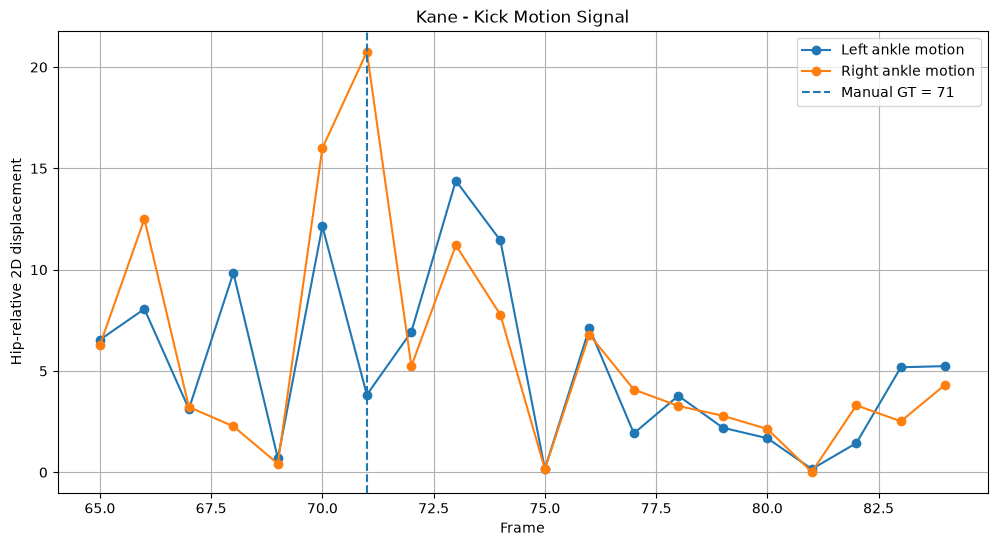

In [132]:
motion_frames = [
    r["frame"]
    for r in motion_records_kane
]

left_motion = [
    r["left_motion"]
    for r in motion_records_kane
]

right_motion = [
    r["right_motion"]
    for r in motion_records_kane
]

plt.figure(figsize=(12, 6))

plt.plot(
    motion_frames,
    left_motion,
    "o-",
    label="Left ankle motion"
)

plt.plot(
    motion_frames,
    right_motion,
    "o-",
    label="Right ankle motion"
)

# 只用于验证
plt.axvline(
    71,
    linestyle="--",
    label="Manual GT = 71"
)

plt.xlabel("Frame")
plt.ylabel("Hip-relative 2D displacement")
plt.title("Kane - Kick Motion Signal")
plt.legend()
plt.grid()

plt.show()

In [133]:
motion_records_pivaric = []

frame_ids = sorted(pivaric_tracked.keys())

for i in range(len(frame_ids) - 1):

    fid1 = frame_ids[i]
    fid2 = frame_ids[i + 1]

    # 不跨 missing frame
    if fid2 - fid1 != 1:
        continue

    kp1 = pivaric_tracked[fid1]["keypoints"]
    kp2 = pivaric_tracked[fid2]["keypoints"]

    required = [11, 12, 15, 16]

    if any(
        np.allclose(kp1[j], 0) or
        np.allclose(kp2[j], 0)
        for j in required
    ):
        continue

    # Hip centres
    hip1 = (kp1[11] + kp1[12]) / 2
    hip2 = (kp2[11] + kp2[12]) / 2

    # Hip-relative ankles
    left1 = kp1[15] - hip1
    right1 = kp1[16] - hip1

    left2 = kp2[15] - hip2
    right2 = kp2[16] - hip2

    # 2D movement
    left_motion = np.linalg.norm(
        left2 - left1
    )

    right_motion = np.linalg.norm(
        right2 - right1
    )

    motion_records_pivaric.append({
        "frame": fid2,
        "left_motion": left_motion,
        "right_motion": right_motion,
        "max_motion": max(
            left_motion,
            right_motion
        )
    })

In [134]:
best_record_pivaric = max(
    motion_records_pivaric,
    key=lambda r: r["max_motion"]
)

auto_kick_pivaric = best_record_pivaric["frame"]

print(
    "Automatic kick candidate:",
    auto_kick_pivaric
)

print(
    "Manual ground truth:",
    142
)

print(
    "Frame error:",
    auto_kick_pivaric - 142
)

print(
    "Absolute frame error:",
    abs(auto_kick_pivaric - 142)
)

print(
    "Time error:",
    round(
        abs(auto_kick_pivaric - 142) / fps,
        3
    ),
    "seconds"
)

Automatic kick candidate: 141
Manual ground truth: 142
Frame error: -1
Absolute frame error: 1
Time error: 0.033 seconds


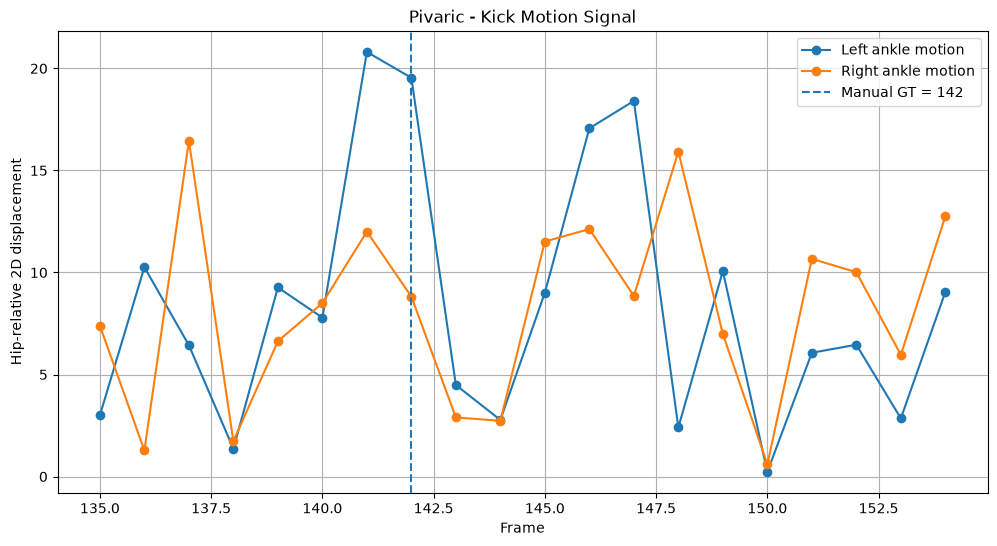

In [135]:
motion_frames = [
    r["frame"]
    for r in motion_records_pivaric
]

left_motion = [
    r["left_motion"]
    for r in motion_records_pivaric
]

right_motion = [
    r["right_motion"]
    for r in motion_records_pivaric
]

plt.figure(figsize=(12, 6))

plt.plot(
    motion_frames,
    left_motion,
    "o-",
    label="Left ankle motion"
)

plt.plot(
    motion_frames,
    right_motion,
    "o-",
    label="Right ankle motion"
)

plt.axvline(
    142,
    linestyle="--",
    label="Manual GT = 142"
)

plt.xlabel("Frame")
plt.ylabel("Hip-relative 2D displacement")
plt.title("Pivaric - Kick Motion Signal")
plt.legend()
plt.grid()

plt.show()

In [136]:
import importlib
import src.kicker_analysis

importlib.reload(src.kicker_analysis)

from src.kicker_analysis import KickerFeatureExtractor

extractor = KickerFeatureExtractor()

In [137]:
frames = []
left_ankles = []
right_ankles = []
left_hips = []
right_hips = []

for fid in sorted(
    falcao_tracked.keys()
):

    kp = falcao_tracked[fid]["keypoints"]

    if (
        np.allclose(kp[11], 0)
        or np.allclose(kp[12], 0)
        or np.allclose(kp[15], 0)
        or np.allclose(kp[16], 0)
    ):
        continue

    frames.append(fid)

    left_hips.append(kp[11])
    right_hips.append(kp[12])

    left_ankles.append(kp[15])
    right_ankles.append(kp[16])

In [138]:
kick_result = extractor.detect_kick_frame_from_pose(
    frames=frames,
    left_ankles=left_ankles,
    right_ankles=right_ankles,
    left_hips=left_hips,
    right_hips=right_hips
)

kick_result

{'kick_frame': 49,
 'peak_motion': 31.47,
 'peak_foot': 'right',
 'frame_pair': (48, 49)}

In [139]:
auto_kick_frame = kick_result["kick_frame"]

foot_result = extractor.classify_kicking_foot_from_motion(
    frames=frames,
    left_ankles=left_ankles,
    right_ankles=right_ankles,
    left_hips=left_hips,
    right_hips=right_hips,
    kick_frame=auto_kick_frame,
    window=3
)

print("Automatic kick frame:", auto_kick_frame)
print("Kicking foot:", foot_result["kicking_foot"])

Automatic kick frame: 49
Kicking foot: right


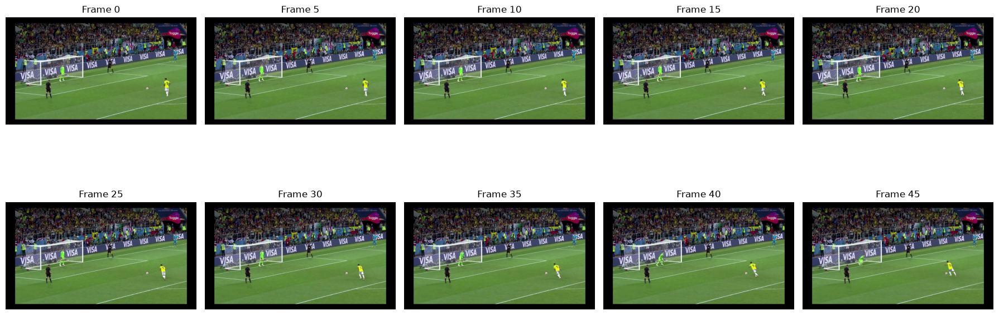

In [140]:
cap = cv2.VideoCapture(falcao_video_path)

sample_frames = list(range(0, 50, 5))

cols = 5
rows = int(np.ceil(len(sample_frames) / cols))

plt.figure(figsize=(18, rows * 4))

for i, fid in enumerate(sample_frames):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    plt.subplot(rows, cols, i + 1)

    plt.imshow(
        cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title(f"Frame {fid}")
    plt.axis("off")

cap.release()

plt.tight_layout()
plt.show()

In [141]:
previous_center = falcao_tracked[40]["center"].copy()

cap = cv2.VideoCapture(falcao_video_path)

for fid in range(39, 9, -1):

    cap.set(cv2.CAP_PROP_POS_FRAMES, fid)
    ret, img = cap.read()

    if not ret:
        continue

    result_pose = pose_model(
        img,
        conf=0.25,
        verbose=False
    )[0]

    if (
        result_pose.boxes is None
        or len(result_pose.boxes) == 0
    ):
        print(f"Frame {fid}: Falcao missing")
        continue

    boxes = result_pose.boxes.xyxy.cpu().numpy()
    keypoints = result_pose.keypoints.xy.cpu().numpy()

    idx, center, distance = find_closest_person(
        boxes,
        previous_center,
        max_move=80
    )

    if idx is None:
        print(
            f"Frame {fid}: Falcao missing "
            f"(nearest={distance:.1f}px)"
        )
        continue

    falcao_tracked[fid] = {
        "box": boxes[idx],
        "keypoints": keypoints[idx],
        "center": center
    }

    previous_center = center

    print(
        f"Frame {fid}: "
        f"center=({center[0]:.1f}, {center[1]:.1f}), "
        f"move={distance:.1f}px"
    )

cap.release()

Frame 39: center=(1016.5, 454.3), move=7.5px
Frame 38: center=(1023.4, 454.8), move=6.9px
Frame 37: center=(1025.4, 460.0), move=5.5px
Frame 36: center=(1028.4, 462.3), move=3.8px
Frame 35: center=(1027.9, 462.5), move=0.5px
Frame 34: Falcao missing (nearest=734.3px)
Frame 33: center=(1035.2, 462.0), move=7.3px
Frame 32: Falcao missing (nearest=742.4px)
Frame 31: center=(1043.2, 465.2), move=8.6px
Frame 30: center=(1047.1, 468.2), move=5.0px
Frame 29: center=(1047.1, 468.2), move=0.0px
Frame 28: Falcao missing (nearest=754.8px)
Frame 27: Falcao missing (nearest=755.5px)
Frame 26: Falcao missing (nearest=756.0px)
Frame 25: Falcao missing (nearest=756.3px)
Frame 24: Falcao missing (nearest=756.6px)
Frame 23: center=(1056.8, 470.5), move=10.0px
Frame 22: center=(1058.8, 469.4), move=2.3px
Frame 21: center=(1061.4, 469.4), move=2.6px
Frame 20: center=(1065.0, 469.1), move=3.6px
Frame 19: center=(1067.0, 469.8), move=2.1px
Frame 18: center=(1068.3, 470.2), move=1.4px
Frame 17: center=(1068.

In [143]:
step_frames = []
left_foot_y = []
right_foot_y = []

for fid in range(10, 50):

    if fid not in falcao_tracked:
        continue

    kp = falcao_tracked[fid]["keypoints"]

    left_ankle = kp[15]
    right_ankle = kp[16]

    if (
        np.allclose(left_ankle, 0)
        or np.allclose(right_ankle, 0)
    ):
        continue

    step_frames.append(fid)
    left_foot_y.append(left_ankle[1])
    right_foot_y.append(right_ankle[1])

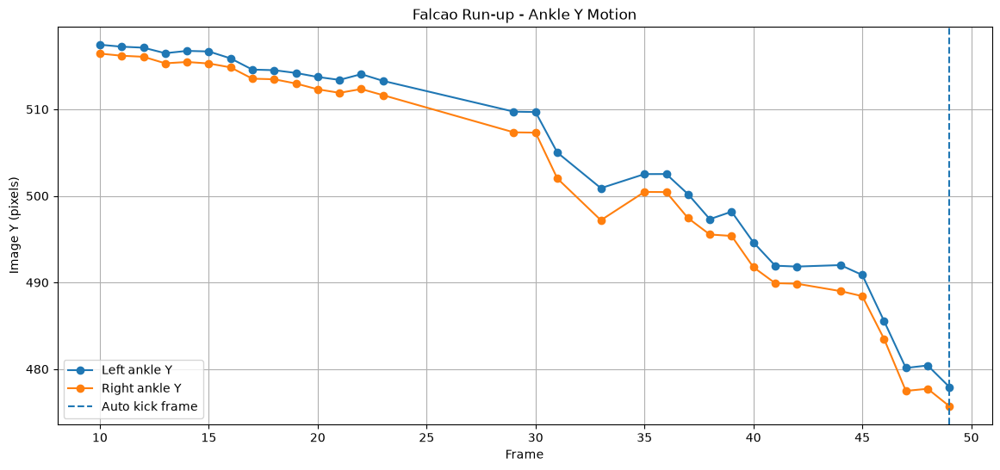

In [144]:
plt.figure(figsize=(14, 6))

plt.plot(
    step_frames,
    left_foot_y,
    "o-",
    label="Left ankle Y"
)

plt.plot(
    step_frames,
    right_foot_y,
    "o-",
    label="Right ankle Y"
)

plt.axvline(
    49,
    linestyle="--",
    label="Auto kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Image Y (pixels)")
plt.title("Falcao Run-up - Ankle Y Motion")
plt.legend()
plt.grid()

plt.show()

In [146]:
step_frames = []

left_leg_extension = []
right_leg_extension = []

for fid in range(10, 50):

    if fid not in falcao_tracked:
        continue

    kp = falcao_tracked[fid]["keypoints"]

    left_hip = kp[11]
    right_hip = kp[12]

    left_ankle = kp[15]
    right_ankle = kp[16]

    if (
        np.allclose(left_hip, 0)
        or np.allclose(right_hip, 0)
        or np.allclose(left_ankle, 0)
        or np.allclose(right_ankle, 0)
    ):
        continue

    # 每条腿自己的 hip -> ankle 距离
    left_distance = np.linalg.norm(
        left_ankle - left_hip
    )

    right_distance = np.linalg.norm(
        right_ankle - right_hip
    )

    step_frames.append(fid)

    left_leg_extension.append(
        left_distance
    )

    right_leg_extension.append(
        right_distance
    )

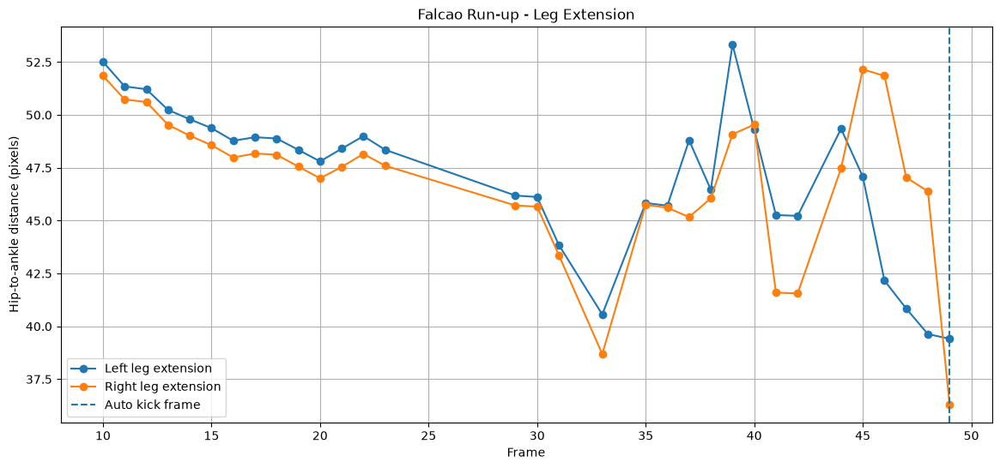

In [147]:
plt.figure(figsize=(14, 6))

plt.plot(
    step_frames,
    left_leg_extension,
    "o-",
    label="Left leg extension"
)

plt.plot(
    step_frames,
    right_leg_extension,
    "o-",
    label="Right leg extension"
)

plt.axvline(
    49,
    linestyle="--",
    label="Auto kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Hip-to-ankle distance (pixels)")
plt.title("Falcao Run-up - Leg Extension")
plt.legend()
plt.grid()

plt.show()

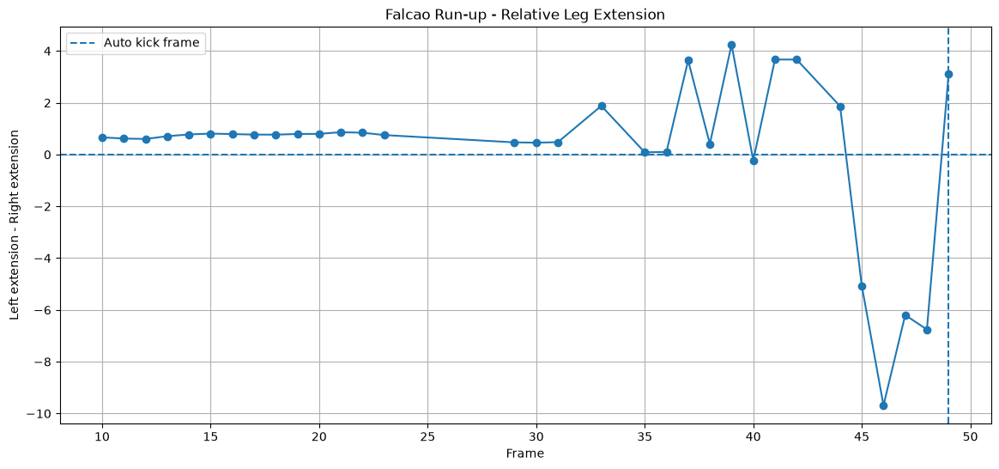

In [148]:
extension_diff = (
    np.array(left_leg_extension)
    - np.array(right_leg_extension)
)

plt.figure(figsize=(14, 6))

plt.plot(
    step_frames,
    extension_diff,
    "o-"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    49,
    linestyle="--",
    label="Auto kick frame"
)

plt.xlabel("Frame")

plt.ylabel(
    "Left extension - Right extension"
)

plt.title(
    "Falcao Run-up - Relative Leg Extension"
)

plt.legend()
plt.grid()

plt.show()

In [149]:
step_motion_records = []

valid_frames = sorted([
    fid for fid in falcao_tracked
    if 10 <= fid <= 48
])

for i in range(len(valid_frames) - 1):

    f1 = valid_frames[i]
    f2 = valid_frames[i + 1]

    if f2 - f1 != 1:
        continue

    kp1 = falcao_tracked[f1]["keypoints"]
    kp2 = falcao_tracked[f2]["keypoints"]

    required = [11, 12, 15, 16]

    if any(
        np.allclose(kp1[j], 0) or
        np.allclose(kp2[j], 0)
        for j in required
    ):
        continue

    hip1 = (kp1[11] + kp1[12]) / 2
    hip2 = (kp2[11] + kp2[12]) / 2

    left1 = kp1[15] - hip1
    left2 = kp2[15] - hip2

    right1 = kp1[16] - hip1
    right2 = kp2[16] - hip2

    left_speed = np.linalg.norm(left2 - left1)
    right_speed = np.linalg.norm(right2 - right1)

    step_motion_records.append({
        "frame": f2,
        "left_speed": left_speed,
        "right_speed": right_speed
    })

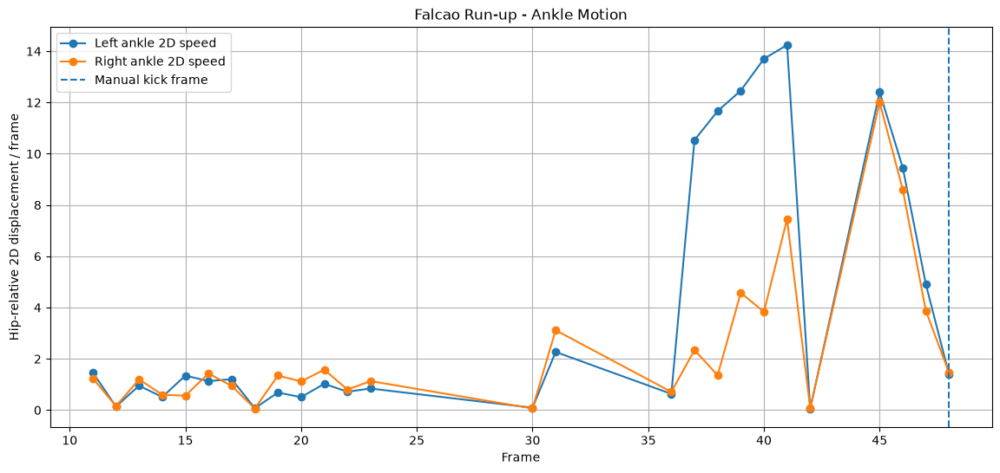

In [150]:
step_motion_frames = [
    r["frame"] for r in step_motion_records
]

left_speed = np.array([
    r["left_speed"] for r in step_motion_records
])

right_speed = np.array([
    r["right_speed"] for r in step_motion_records
])

plt.figure(figsize=(14, 6))

plt.plot(
    step_motion_frames,
    left_speed,
    "o-",
    label="Left ankle 2D speed"
)

plt.plot(
    step_motion_frames,
    right_speed,
    "o-",
    label="Right ankle 2D speed"
)

plt.axvline(
    48,
    linestyle="--",
    label="Manual kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Hip-relative 2D displacement / frame")
plt.title("Falcao Run-up - Ankle Motion")
plt.legend()
plt.grid()

plt.show()

In [152]:
from scipy.signal import find_peaks

left_speed_arr = np.array(left_speed)
right_speed_arr = np.array(right_speed)

kernel = np.ones(3) / 3

left_smooth = np.convolve(
    left_speed_arr,
    kernel,
    mode="same"
)

right_smooth = np.convolve(
    right_speed_arr,
    kernel,
    mode="same"
)

left_peaks, _ = find_peaks(
    left_smooth,
    distance=3,
    prominence=1.5
)

right_peaks, _ = find_peaks(
    right_smooth,
    distance=3,
    prominence=1.5
)

left_peak_frames = [
    step_motion_frames[i]
    for i in left_peaks
]

right_peak_frames = [
    step_motion_frames[i]
    for i in right_peaks
]

print("Left swing candidates :", left_peak_frames)
print("Right swing candidates:", right_peak_frames)

Left swing candidates : [40, 46]
Right swing candidates: [40, 46]


In [154]:
def joint_angle(a, b, c):
    """
    Angle ABC in degrees.
    b is the joint vertex.
    """
    ba = a - b
    bc = c - b

    denom = np.linalg.norm(ba) * np.linalg.norm(bc)

    if denom < 1e-6:
        return np.nan

    cos_angle = np.dot(ba, bc) / denom
    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    return np.degrees(np.arccos(cos_angle))

In [155]:
knee_frames = []
left_knee_angles = []
right_knee_angles = []

for fid in range(10, 50):

    if fid not in falcao_tracked:
        continue

    kp = falcao_tracked[fid]["keypoints"]

    # Left leg
    left_hip = kp[11]
    left_knee = kp[13]
    left_ankle = kp[15]

    # Right leg
    right_hip = kp[12]
    right_knee = kp[14]
    right_ankle = kp[16]

    required = [
        left_hip, left_knee, left_ankle,
        right_hip, right_knee, right_ankle
    ]

    if any(np.allclose(p, 0) for p in required):
        continue

    left_angle = joint_angle(
        left_hip,
        left_knee,
        left_ankle
    )

    right_angle = joint_angle(
        right_hip,
        right_knee,
        right_ankle
    )

    knee_frames.append(fid)
    left_knee_angles.append(left_angle)
    right_knee_angles.append(right_angle)

In [156]:
knee_frames = []
left_knee_angles = []
right_knee_angles = []

for fid in range(10, 50):

    if fid not in falcao_tracked:
        continue

    kp = falcao_tracked[fid]["keypoints"]

    # Left leg
    left_hip = kp[11]
    left_knee = kp[13]
    left_ankle = kp[15]

    # Right leg
    right_hip = kp[12]
    right_knee = kp[14]
    right_ankle = kp[16]

    required = [
        left_hip, left_knee, left_ankle,
        right_hip, right_knee, right_ankle
    ]

    if any(np.allclose(p, 0) for p in required):
        continue

    left_angle = joint_angle(
        left_hip,
        left_knee,
        left_ankle
    )

    right_angle = joint_angle(
        right_hip,
        right_knee,
        right_ankle
    )

    knee_frames.append(fid)
    left_knee_angles.append(left_angle)
    right_knee_angles.append(right_angle)

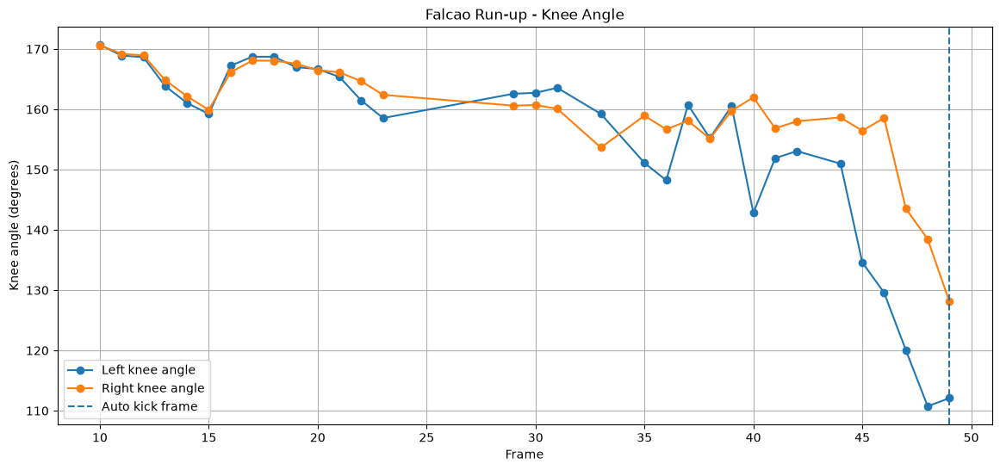

In [157]:
plt.figure(figsize=(14, 6))

plt.plot(
    knee_frames,
    left_knee_angles,
    "o-",
    label="Left knee angle"
)

plt.plot(
    knee_frames,
    right_knee_angles,
    "o-",
    label="Right knee angle"
)

plt.axvline(
    49,
    linestyle="--",
    label="Auto kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Knee angle (degrees)")
plt.title("Falcao Run-up - Knee Angle")
plt.legend()
plt.grid()

plt.show()

In [158]:
body_frames = []
body_centers = []

for fid in range(10, 49):

    if fid not in falcao_tracked:
        continue

    kp = falcao_tracked[fid]["keypoints"]

    left_hip = kp[11]
    right_hip = kp[12]

    if (
        np.allclose(left_hip, 0)
        or np.allclose(right_hip, 0)
    ):
        continue

    hip_center = (
        left_hip + right_hip
    ) / 2

    body_frames.append(fid)
    body_centers.append(hip_center)

body_centers = np.array(body_centers)

runup_vector = (
    body_centers[-1]
    - body_centers[0]
)

runup_direction = (
    runup_vector
    / np.linalg.norm(runup_vector)
)

print("Run-up vector:", runup_vector)
print("Run-up direction:", runup_direction)

Run-up vector: [    -87.688     -23.076]
Run-up direction: [   -0.96707    -0.25449]


In [159]:
projection_frames = []

left_projection = []
right_projection = []

for fid in range(10, 49):

    if fid not in falcao_tracked:
        continue

    kp = falcao_tracked[fid]["keypoints"]

    left_hip = kp[11]
    right_hip = kp[12]

    left_ankle = kp[15]
    right_ankle = kp[16]

    required = [
        left_hip,
        right_hip,
        left_ankle,
        right_ankle
    ]

    if any(
        np.allclose(p, 0)
        for p in required
    ):
        continue

    hip_center = (
        left_hip + right_hip
    ) / 2

    left_relative = (
        left_ankle - hip_center
    )

    right_relative = (
        right_ankle - hip_center
    )

    # 投影到助跑方向
    left_p = np.dot(
        left_relative,
        runup_direction
    )

    right_p = np.dot(
        right_relative,
        runup_direction
    )

    projection_frames.append(fid)
    left_projection.append(left_p)
    right_projection.append(right_p)

In [160]:
foot_order = (
    np.array(left_projection)
    - np.array(right_projection)
)

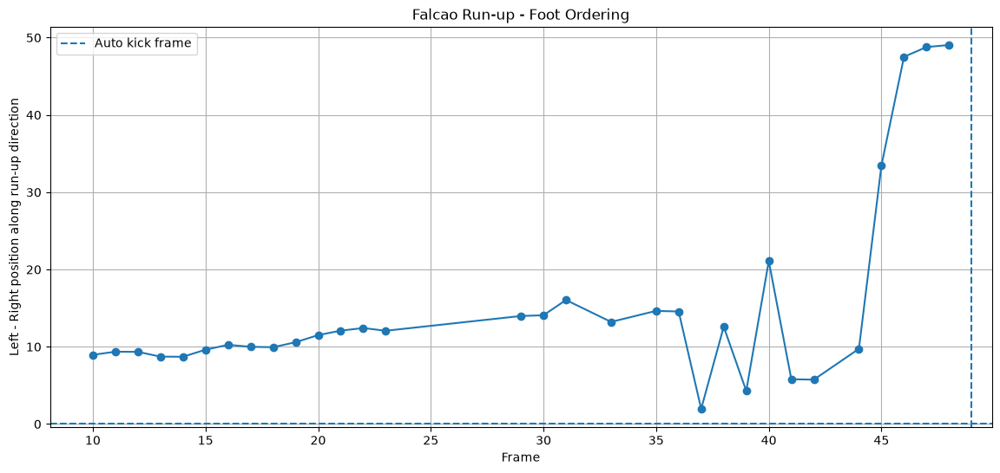

In [161]:
plt.figure(figsize=(14, 6))

plt.plot(
    projection_frames,
    foot_order,
    "o-"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    49,
    linestyle="--",
    label="Auto kick frame"
)

plt.xlabel("Frame")
plt.ylabel(
    "Left - Right position along run-up direction"
)

plt.title(
    "Falcao Run-up - Foot Ordering"
)

plt.legend()
plt.grid()

plt.show()

In [162]:
contact_frames = []
left_vel = []
right_vel = []

valid_frames = sorted([
    fid
    for fid in falcao_tracked
    if 10 <= fid <= 48
])

for i in range(len(valid_frames) - 1):

    f1 = valid_frames[i]
    f2 = valid_frames[i + 1]

    # 不跨 missing frame
    if f2 - f1 != 1:
        continue

    kp1 = falcao_tracked[f1]["keypoints"]
    kp2 = falcao_tracked[f2]["keypoints"]

    left1 = kp1[15]
    left2 = kp2[15]

    right1 = kp1[16]
    right2 = kp2[16]

    if (
        np.allclose(left1, 0)
        or np.allclose(left2, 0)
        or np.allclose(right1, 0)
        or np.allclose(right2, 0)
    ):
        continue

    left_speed = np.linalg.norm(
        left2 - left1
    )

    right_speed = np.linalg.norm(
        right2 - right1
    )

    contact_frames.append(f2)
    left_vel.append(left_speed)
    right_vel.append(right_speed)

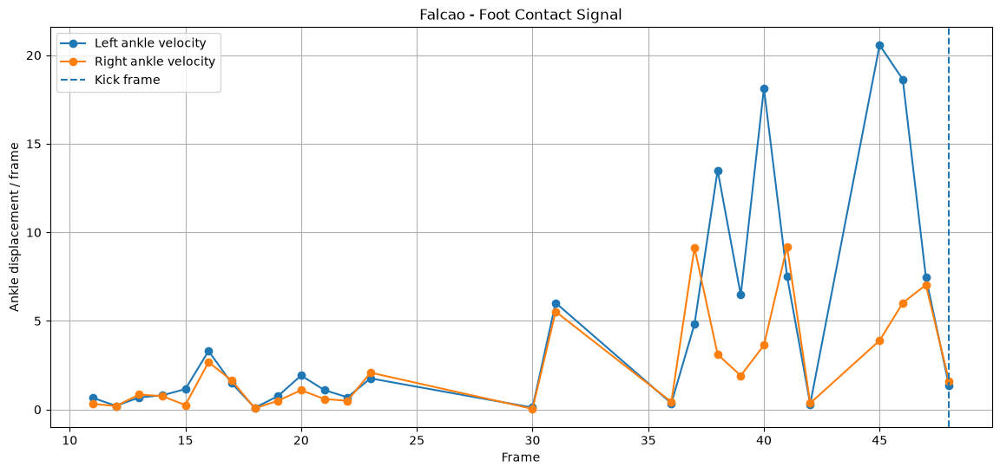

In [163]:
plt.figure(figsize=(14, 6))

plt.plot(
    contact_frames,
    left_vel,
    "o-",
    label="Left ankle velocity"
)

plt.plot(
    contact_frames,
    right_vel,
    "o-",
    label="Right ankle velocity"
)

plt.axvline(
    48,
    linestyle="--",
    label="Kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Ankle displacement / frame")
plt.title("Falcao - Foot Contact Signal")
plt.legend()
plt.grid()

plt.show()

In [164]:
support_records = []

valid_frames = sorted([
    fid for fid in falcao_tracked
    if 10 <= fid <= 48
])

for fid in valid_frames:

    kp = falcao_tracked[fid]["keypoints"]

    left = kp[15]
    right = kp[16]

    if (
        np.allclose(left, 0)
        or np.allclose(right, 0)
    ):
        continue

    support_records.append({
        "frame": fid,
        "left_y": left[1],
        "right_y": right[1],
        "y_diff": left[1] - right[1]
    })

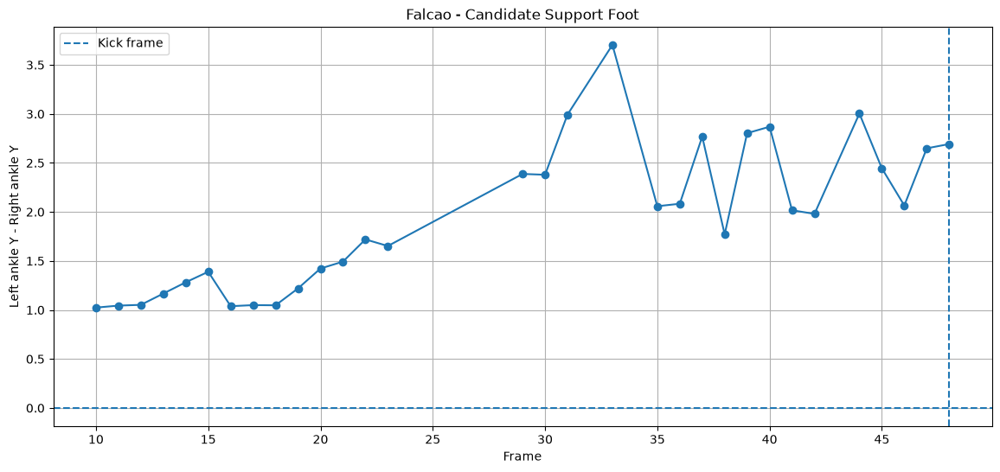

In [165]:
support_frames = [
    r["frame"]
    for r in support_records
]

support_diff = [
    r["y_diff"]
    for r in support_records
]

plt.figure(figsize=(14, 6))

plt.plot(
    support_frames,
    support_diff,
    "o-"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    48,
    linestyle="--",
    label="Kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Left ankle Y - Right ankle Y")
plt.title("Falcao - Candidate Support Foot")
plt.legend()
plt.grid()

plt.show()

In [166]:
import numpy as np

frames_arr = np.array(contact_frames)
left_vel_arr = np.array(left_vel)
right_vel_arr = np.array(right_vel)

print("Frames:", len(frames_arr))
print("Left velocity range:",
      left_vel_arr.min(), "->", left_vel_arr.max())
print("Right velocity range:",
      right_vel_arr.min(), "->", right_vel_arr.max())

Frames: 26
Left velocity range: 0.095856935 -> 20.57474
Right velocity range: 0.035759155 -> 9.1916065


In [167]:
left_threshold = np.percentile(
    left_vel_arr,
    35
)

right_threshold = np.percentile(
    right_vel_arr,
    35
)

print(
    "Left contact threshold:",
    round(left_threshold, 2)
)

print(
    "Right contact threshold:",
    round(right_threshold, 2)
)

Left contact threshold: 0.79
Right contact threshold: 0.57


In [168]:
def find_contact_periods(
    frames,
    velocity,
    threshold,
    min_duration=2
):
    """
    Find continuous low-velocity periods.

    Each period represents a possible
    foot-ground contact / stance phase.
    """

    contacts = []

    start = None
    previous_frame = None

    for frame, vel in zip(
        frames,
        velocity
    ):

        is_low_speed = (
            vel <= threshold
        )

        if is_low_speed:

            if (
                start is None
                or previous_frame is None
                or frame - previous_frame != 1
            ):
                start = frame

            previous_frame = frame

        else:

            if start is not None:

                end = previous_frame

                duration = (
                    end - start + 1
                )

                if duration >= min_duration:
                    contacts.append(
                        (start, end)
                    )

                start = None
                previous_frame = None

    # 最后一段
    if start is not None:

        end = previous_frame

        duration = end - start + 1

        if duration >= min_duration:
            contacts.append(
                (start, end)
            )

    return contacts

In [169]:
left_contacts = find_contact_periods(
    frames_arr,
    left_vel_arr,
    left_threshold,
    min_duration=2
)

right_contacts = find_contact_periods(
    frames_arr,
    right_vel_arr,
    right_threshold,
    min_duration=2
)

print(
    "Left stance periods :",
    left_contacts
)

print(
    "Right stance periods:",
    right_contacts
)

Left stance periods : [(np.int64(11), np.int64(13)), (np.int64(18), np.int64(19))]
Right stance periods: [(np.int64(11), np.int64(12)), (np.int64(18), np.int64(19))]


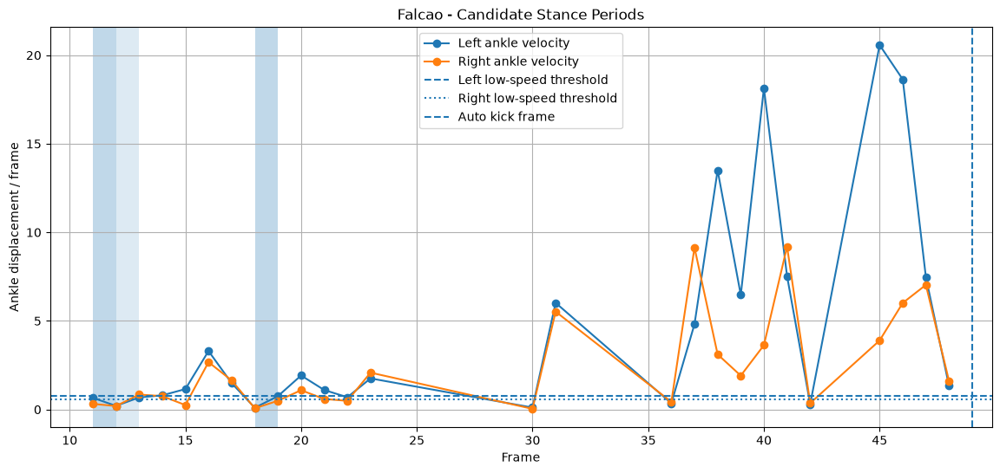

In [170]:
plt.figure(figsize=(14, 6))

plt.plot(
    frames_arr,
    left_vel_arr,
    "o-",
    label="Left ankle velocity"
)

plt.plot(
    frames_arr,
    right_vel_arr,
    "o-",
    label="Right ankle velocity"
)

plt.axhline(
    left_threshold,
    linestyle="--",
    label="Left low-speed threshold"
)

plt.axhline(
    right_threshold,
    linestyle=":",
    label="Right low-speed threshold"
)

for start, end in left_contacts:
    plt.axvspan(
        start,
        end,
        alpha=0.15
    )

for start, end in right_contacts:
    plt.axvspan(
        start,
        end,
        alpha=0.15
    )

plt.axvline(
    49,
    linestyle="--",
    label="Auto kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Ankle displacement / frame")
plt.title("Falcao - Candidate Stance Periods")
plt.legend()
plt.grid()

plt.show()

In [171]:
min_foot_velocity = np.minimum(
    left_vel_arr,
    right_vel_arr
)

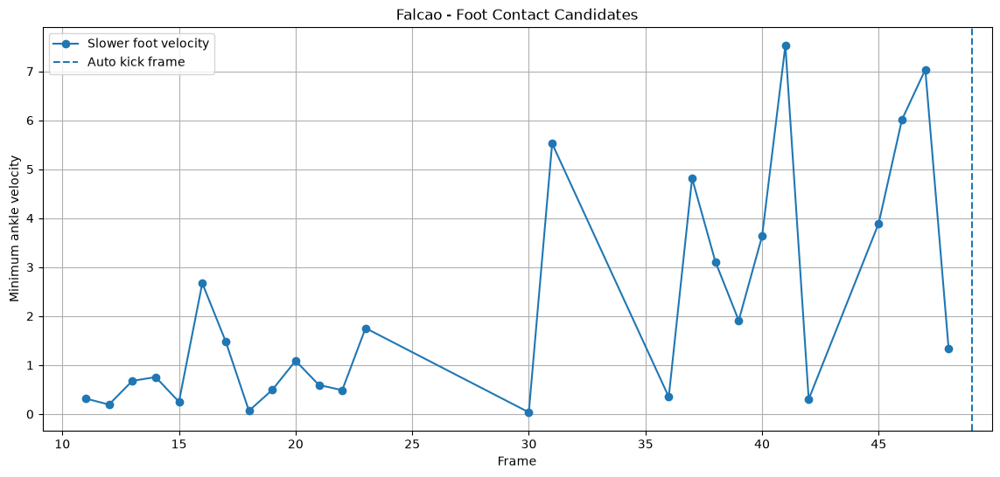

In [172]:
plt.figure(figsize=(14, 6))

plt.plot(
    frames_arr,
    min_foot_velocity,
    "o-",
    label="Slower foot velocity"
)

plt.axvline(
    49,
    linestyle="--",
    label="Auto kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Minimum ankle velocity")
plt.title("Falcao - Foot Contact Candidates")
plt.legend()
plt.grid()

plt.show()

In [173]:
contact_idx, properties = find_peaks(
    -min_foot_velocity,
    distance=4,
    prominence=0.8
)

contact_candidates = [
    frames_arr[i]
    for i in contact_idx
]

print(
    "Contact candidates:",
    contact_candidates
)

Contact candidates: [np.int64(18), np.int64(30), np.int64(42)]


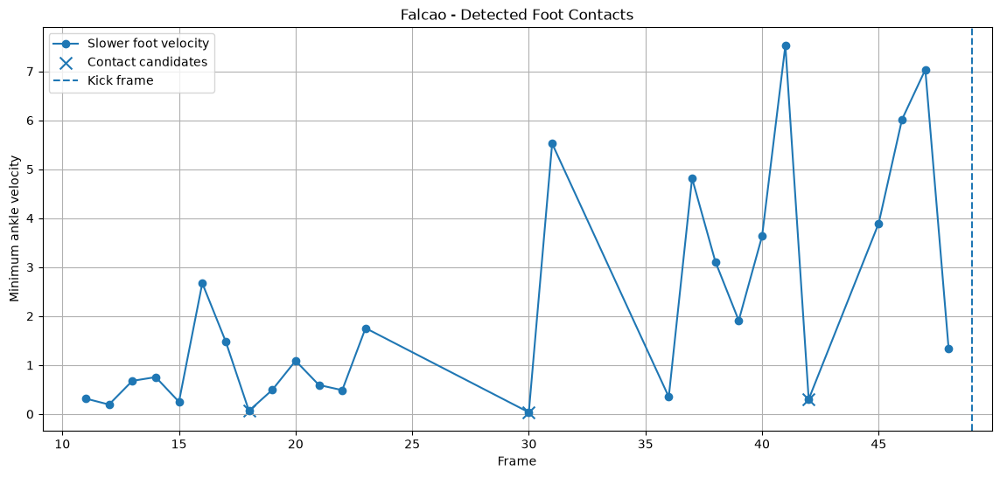

In [174]:
plt.figure(figsize=(14, 6))

plt.plot(
    frames_arr,
    min_foot_velocity,
    "o-",
    label="Slower foot velocity"
)

plt.scatter(
    contact_candidates,
    min_foot_velocity[contact_idx],
    s=100,
    marker="x",
    label="Contact candidates"
)

plt.axvline(
    49,
    linestyle="--",
    label="Kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Minimum ankle velocity")
plt.title("Falcao - Detected Foot Contacts")
plt.legend()
plt.grid()

plt.show()

In [175]:
contact_data = []

valid_frames = sorted([
    fid
    for fid in falcao_tracked
    if 10 <= fid <= 48
])

for i in range(len(valid_frames) - 1):

    f1 = valid_frames[i]
    f2 = valid_frames[i + 1]

    if f2 - f1 != 1:
        continue

    kp1 = falcao_tracked[f1]["keypoints"]
    kp2 = falcao_tracked[f2]["keypoints"]

    required = [11, 12, 15, 16]

    if any(
        np.allclose(kp1[j], 0)
        or np.allclose(kp2[j], 0)
        for j in required
    ):
        continue

    hip1 = (kp1[11] + kp1[12]) / 2
    hip2 = (kp2[11] + kp2[12]) / 2

    left1 = kp1[15] - hip1
    left2 = kp2[15] - hip2

    right1 = kp1[16] - hip1
    right2 = kp2[16] - hip2

    left_v = np.linalg.norm(left2 - left1)
    right_v = np.linalg.norm(right2 - right1)

    contact_data.append({
        "frame": f2,
        "left_v": left_v,
        "right_v": right_v
    })

In [176]:
contact_frames2 = np.array([
    d["frame"] for d in contact_data
])

left_v = np.array([
    d["left_v"] for d in contact_data
])

right_v = np.array([
    d["right_v"] for d in contact_data
])

left_norm = left_v / (np.median(left_v) + 1e-6)
right_norm = right_v / (np.median(right_v) + 1e-6)

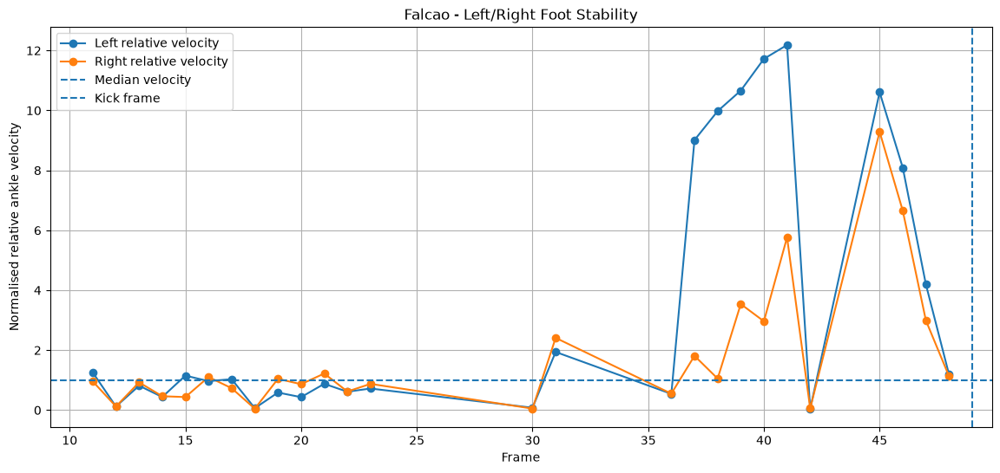

In [177]:
plt.figure(figsize=(14, 6))

plt.plot(
    contact_frames2,
    left_norm,
    "o-",
    label="Left relative velocity"
)

plt.plot(
    contact_frames2,
    right_norm,
    "o-",
    label="Right relative velocity"
)

plt.axhline(
    1.0,
    linestyle="--",
    label="Median velocity"
)

plt.axvline(
    49,
    linestyle="--",
    label="Kick frame"
)

plt.xlabel("Frame")
plt.ylabel("Normalised relative ankle velocity")
plt.title("Falcao - Left/Right Foot Stability")
plt.legend()
plt.grid()

plt.show()

In [178]:
from src.homography import PitchHomographyTransformer

transformer = PitchHomographyTransformer()

print(transformer)

In [179]:
fid = 10

kp = falcao_tracked[fid]["keypoints"]

left_ankle = kp[15]
right_ankle = kp[16]

print("Left ankle pixel :", left_ankle)
print("Right ankle pixel:", right_ankle)

left_pitch = transformer.transform_trajectory([
    tuple(left_ankle)
])

right_pitch = transformer.transform_trajectory([
    tuple(right_ankle)
])

print("Left ankle pitch :", left_pitch)
print("Right ankle pitch:", right_pitch)

Left ankle pixel : [     1074.5      517.45]
Right ankle pixel: [       1084      516.43]
Left ankle pitch : [(np.float32(1074.5106), np.float32(517.4547))]
Right ankle pitch: [(np.float32(1084.0417), np.float32(516.4306))]


In [184]:
%pip install ipympl


   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 16.6 MB/s  0:00:00

   -------------------- ------------------- 2/4 [ipywidgets]
   ---------------------------------------- 4/4 [ipympl]

Note: you may need to restart the kernel to use updated packages.


In [185]:
%matplotlib widget

RuntimeError: 'widget' is not a recognised GUI loop or backend name

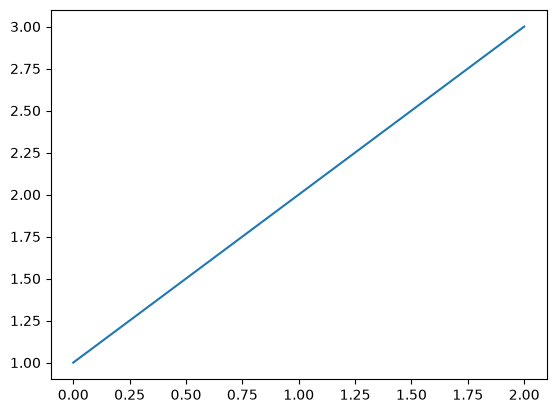

In [186]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot([1, 2, 3])
plt.show()

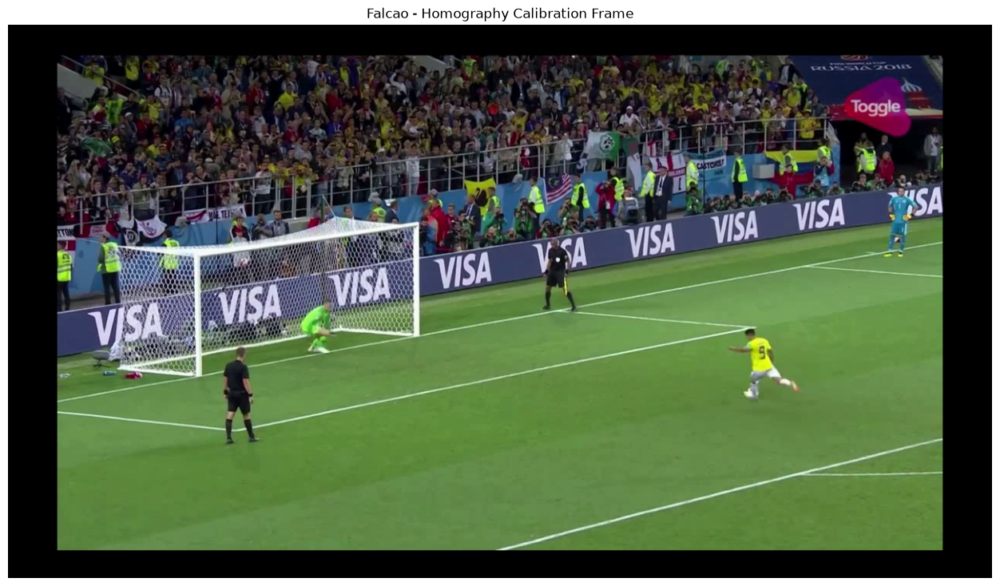

In [187]:
fid = 48

cap = cv2.VideoCapture(falcao_video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, fid)

ret, calibration_frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("无法读取 calibration frame")

plt.figure(figsize=(16, 9))

plt.imshow(
    cv2.cvtColor(
        calibration_frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Falcao - Homography Calibration Frame")
plt.axis("off")
plt.show()

In [190]:
%matplotlib inline

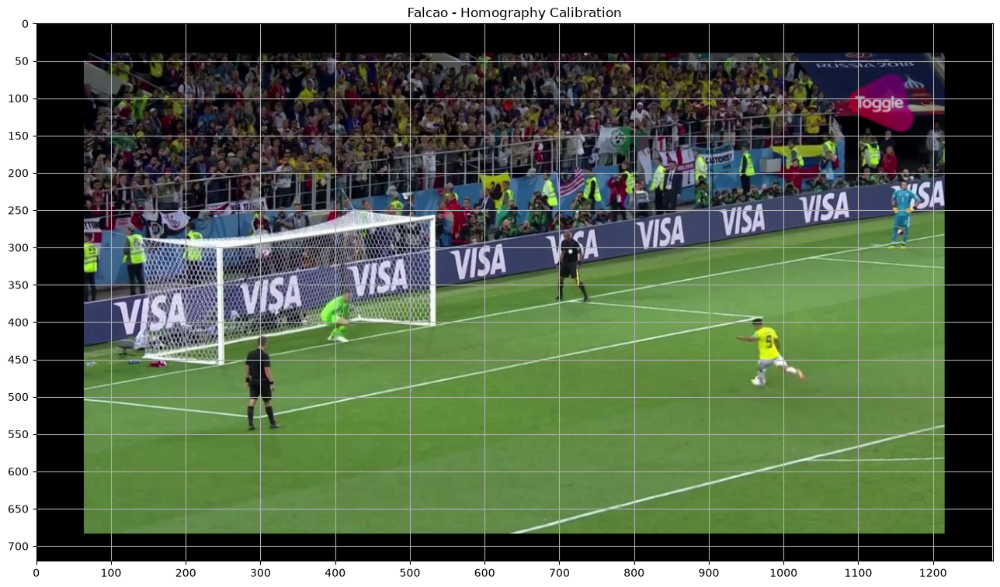

In [191]:
plt.figure(figsize=(16, 9))

plt.imshow(
    cv2.cvtColor(
        calibration_frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Falcao - Homography Calibration")

plt.xlim(0, calibration_frame.shape[1])
plt.ylim(calibration_frame.shape[0], 0)

plt.xticks(
    np.arange(
        0,
        calibration_frame.shape[1] + 1,
        100
    )
)

plt.yticks(
    np.arange(
        0,
        calibration_frame.shape[0] + 1,
        50
    )
)

plt.grid()

plt.show()

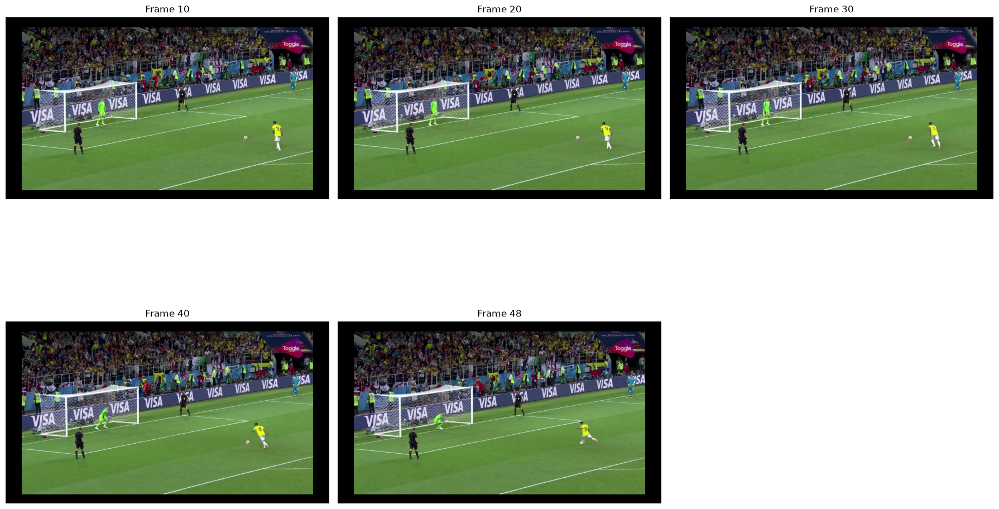

In [193]:
candidate_frames = [10, 20, 30, 40, 48]

cap = cv2.VideoCapture(falcao_video_path)

plt.figure(figsize=(18, 12))

for i, fid in enumerate(candidate_frames):

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        fid
    )

    ret, img = cap.read()

    if not ret:
        continue

    plt.subplot(2, 3, i + 1)

    plt.imshow(
        cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title(f"Frame {fid}")
    plt.axis("off")

cap.release()

plt.tight_layout()
plt.show()

In [195]:
fid = 10

cap = cv2.VideoCapture(falcao_video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, fid)

ret, homo_frame = cap.read()
cap.release()

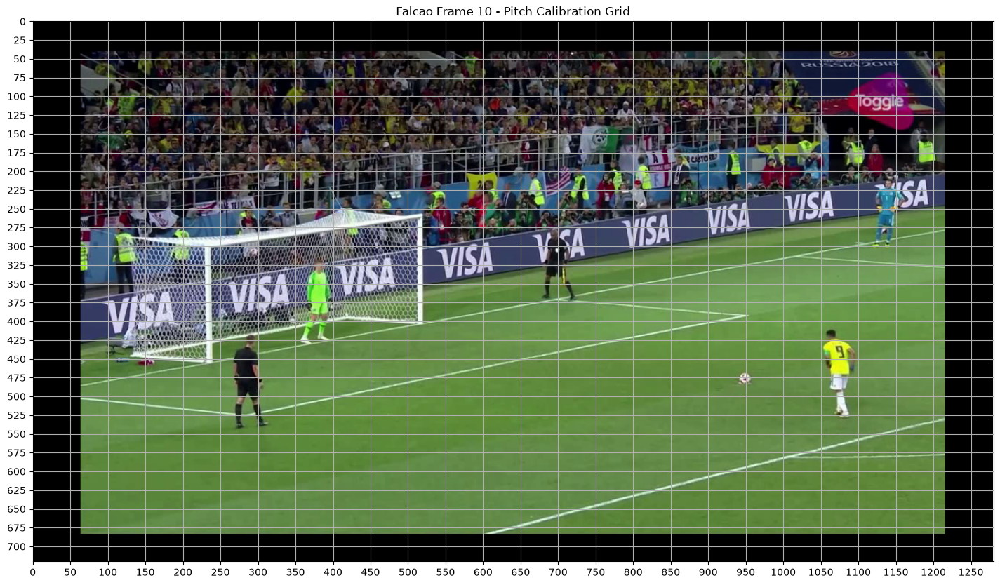

In [196]:
plt.figure(figsize=(18, 10))

plt.imshow(
    cv2.cvtColor(
        homo_frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.xlim(0, homo_frame.shape[1])
plt.ylim(homo_frame.shape[0], 0)

plt.xticks(
    np.arange(
        0,
        homo_frame.shape[1] + 1,
        50
    )
)

plt.yticks(
    np.arange(
        0,
        homo_frame.shape[0] + 1,
        25
    )
)

plt.grid()

plt.title(
    "Falcao Frame 10 - Pitch Calibration Grid"
)

plt.show()

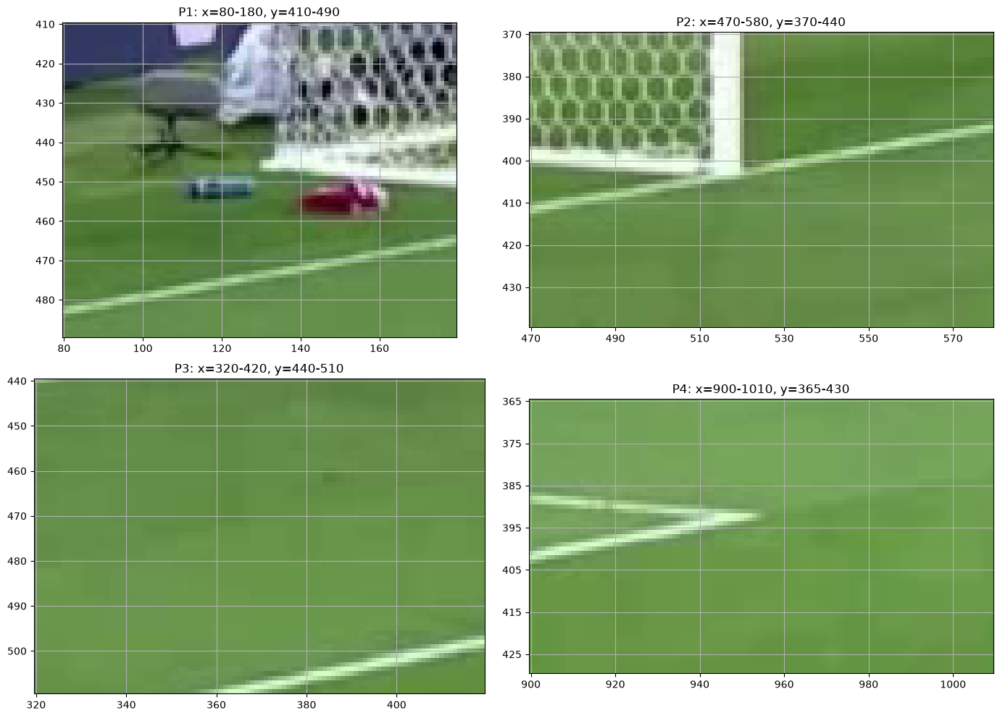

In [197]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

regions = [
    ("P1", 80, 180, 410, 490),
    ("P2", 470, 580, 370, 440),
    ("P3", 320, 420, 440, 510),
    ("P4", 900, 1010, 365, 430),
]

for ax, (name, x1, x2, y1, y2) in zip(
    axes.flat,
    regions
):
    crop = homo_frame[y1:y2, x1:x2]

    ax.imshow(
        cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2RGB
        )
    )

    ax.set_title(
        f"{name}: x={x1}-{x2}, y={y1}-{y2}"
    )

    # 坐标仍然显示成原图坐标
    ax.set_xticks(
        np.arange(0, x2 - x1, 20)
    )
    ax.set_xticklabels(
        np.arange(x1, x2, 20)
    )

    ax.set_yticks(
        np.arange(0, y2 - y1, 10)
    )
    ax.set_yticklabels(
        np.arange(y1, y2, 10)
    )

    ax.grid()

plt.tight_layout()
plt.show()

# Vision II — Step Counting (Final Reproducible Pipeline)

本节是步数确认的最终、可复现入口。前面的单人探索单元保留作开发记录；正式结果统一由
`src.step_pipeline` 和 `scripts/run_step_counting.py` 产生。

批处理严格读取 `configs/penalty_slicing_manifest.yaml`，只处理其中 39 个 canonical clips，
不会把目录里的旧文件名或重复片段算作额外点球。


## 计步定义与人工复核规则

一步定义为：**有意助跑开始后，一只脚从摆动转为一次新的落地/支撑**。

- 助跑开始时已经着地的脚不计为新的一步。
- 射门前最后一次非踢球脚（支撑脚）落地计一步。
- 踢球脚触球本身不计步，射门后的恢复落地也不计步。
- `review_required=True`、`status != "ok"` 或低覆盖率/低置信度的结果必须人工复核；
  流程不会为了得到一个数字而强制至少计 1 步。

`step_frames` 是每次落地对应的证据帧，`step_feet` 给出左右脚顺序；详细逐帧证据保存在
`outputs/step_diagnostics.json`。


In [ ]:
from pathlib import Path
import csv
import json
import subprocess
import sys

import yaml
from IPython.display import display
from ultralytics import YOLO

# Locate the repository even if Jupyter was launched from a subdirectory.
_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (_start, *_start.parents)
        if (candidate / "src" / "step_pipeline.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root containing src/step_pipeline.py"
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.step_pipeline import process_video_steps

MANIFEST_PATH = PROJECT_ROOT / "configs" / "penalty_slicing_manifest.yaml"
CLIPS_DIR = PROJECT_ROOT / "data" / "raw_clips"
OUTPUT_CSV = PROJECT_ROOT / "data" / "processed" / "penalty_step_counts.csv"
DIAGNOSTICS_JSON = PROJECT_ROOT / "outputs" / "step_diagnostics.json"
RUNNER_PATH = PROJECT_ROOT / "scripts" / "run_step_counting.py"
MODEL_PATH = PROJECT_ROOT / "models" / "weights" / "yolo11n_pose.pt"

with MANIFEST_PATH.open("r", encoding="utf-8") as handle:
    manifest_data = yaml.safe_load(handle)

canonical_clip_ids = [
    f"{match_key}_p{int(penalty['number']):02d}_{penalty['kicker']}"
    for match_key, match in manifest_data.items()
    for penalty in match["penalties"]
]
assert len(canonical_clip_ids) == 39, (
    f"Expected 39 canonical clips, found {len(canonical_clip_ids)}"
)
assert len(canonical_clip_ids) == len(set(canonical_clip_ids)), (
    "Canonical clip IDs must be unique"
)

missing_clips = [
    clip_id
    for clip_id in canonical_clip_ids
    if not (CLIPS_DIR / f"{clip_id}.mp4").is_file()
]
print(f"Canonical penalties in manifest: {len(canonical_clip_ids)}")
print(f"Missing canonical clips: {len(missing_clips)}")
if missing_clips:
    display(missing_clips)


## 1. 先验证一个视频

下面用 manifest 的第一条（Falcao）完成一次端到端调用。模型只加载一次；返回字典包含踢球者轨迹、
kick frame、踢球脚、步数、落地帧、置信度和 QA 标记。确认这个结果能正常产生后再运行 39 人批处理。


In [ ]:
step_pose_model = YOLO(str(MODEL_PATH))

example_clip_id = canonical_clip_ids[0]
example_video = CLIPS_DIR / f"{example_clip_id}.mp4"
example_result = process_video_steps(
    video_path=str(example_video),
    model=step_pose_model,
    clip_id=example_clip_id,
    roi_mode="auto",
    pose_conf=0.10,
    predict_kwargs={"imgsz": 640, "conf": 0.10},
)

example_fields = [
    "clip_id",
    "status",
    "runup_start_frame",
    "kick_frame",
    "kicking_foot",
    "step_count",
    "step_frames",
    "step_feet",
    "review_required",
    "auto_accepted",
    "qa_warnings",
]
display({field: example_result.get(field) for field in example_fields})


## 2. 按 manifest 运行全部 39 个 canonical clips

这是正式批处理单元，运行时间会明显长于单视频验证。CLI 内部只加载一次 pose model，并调用
`process_manifest_steps`；即使个别片段失败，也会为每个 manifest 条目保留一行并标记复核。

退出码 `0` 表示没有处理失败；退出码 `1` 表示至少一条失败，但 CSV 和 diagnostics 仍会写出，
应继续运行下面的复核单元定位问题。


In [ ]:
batch_command = [
    sys.executable,
    str(RUNNER_PATH),
    "--model",
    str(MODEL_PATH),
    "--imgsz",
    "640",
    "--conf",
    "0.10",
    "--manifest",
    str(MANIFEST_PATH),
    "--clips-dir",
    str(CLIPS_DIR),
    "--output-csv",
    str(OUTPUT_CSV),
    "--diagnostics-json",
    str(DIAGNOSTICS_JSON),
]

print("Processing exactly 39 canonical penalties from the manifest...")
batch_process = subprocess.run(batch_command, cwd=str(PROJECT_ROOT), check=False)
print(f"Batch exit code: {batch_process.returncode}")
print(f"CSV: {OUTPUT_CSV}")
print(f"Diagnostics: {DIAGNOSTICS_JSON}")


## 3. 读取结果并列出需要确认的球员

首张表展示全部 39 行的核心字段。第二张表只保留 `review_required=True` 或处理失败的球员；
这些条目应结合 `step_frames`、`step_feet`、`qa_warnings` 和 diagnostics 中的姿态证据人工确认。


In [ ]:
if not OUTPUT_CSV.is_file():
    raise FileNotFoundError("Run the 39-clip batch cell before reading results")

with OUTPUT_CSV.open("r", encoding="utf-8", newline="") as handle:
    step_rows = list(csv.DictReader(handle))

assert len(step_rows) == 39, f"Expected 39 CSV rows, found {len(step_rows)}"

result_columns = [
    "clip_id",
    "kicker",
    "team",
    "status",
    "kicking_foot",
    "step_count",
    "step_frames",
    "step_feet",
    "confidence",
    "review_required",
    "qa_warnings",
]

def _is_true(value):
    return str(value).strip().lower() == "true"

try:
    import pandas as pd
except ImportError:
    print("pandas is unavailable; displaying plain Python rows.")
    display([{key: row.get(key) for key in result_columns} for row in step_rows])
else:
    display(pd.DataFrame(step_rows)[result_columns])

review_rows = [
    row
    for row in step_rows
    if _is_true(row.get("review_required"))
    or str(row.get("status", "")).strip().lower() != "ok"
]
review_columns = [
    "clip_id",
    "kicker",
    "status",
    "step_count",
    "step_frames",
    "step_feet",
    "confidence",
    "qa_warnings",
    "error",
]

print(f"Auto-accepted: {len(step_rows) - len(review_rows)} / {len(step_rows)}")
print(f"Manual review required: {len(review_rows)} / {len(step_rows)}")
if review_rows:
    if "pd" in globals():
        display(pd.DataFrame(review_rows)[review_columns])
    else:
        display([{key: row.get(key) for key in review_columns} for row in review_rows])
else:
    print("No rows are currently flagged for manual review.")


In [ ]:
if not DIAGNOSTICS_JSON.is_file():
    raise FileNotFoundError("Diagnostics JSON was not produced by the batch run")

with DIAGNOSTICS_JSON.open("r", encoding="utf-8") as handle:
    step_diagnostics = json.load(handle)

diagnostics_by_clip = {
    item["clip_id"]: item
    for item in step_diagnostics
}
review_evidence = [
    {
        "clip_id": row["clip_id"],
        "step_count": diagnostics_by_clip[row["clip_id"]].get("step_count"),
        "step_frames": diagnostics_by_clip[row["clip_id"]].get("step_frames"),
        "step_feet": diagnostics_by_clip[row["clip_id"]].get("step_feet"),
        "qa_warnings": diagnostics_by_clip[row["clip_id"]].get("qa_warnings"),
    }
    for row in review_rows
    if row["clip_id"] in diagnostics_by_clip
]
display(review_evidence)


## 完成标准

当 CSV 正好有 39 行、每行都有 `step_count`，并且复核清单中的异常都已人工确认后，
才将“每名球员的步数”视为完成。最终提交应同时保留：

1. `data/processed/penalty_step_counts.csv`（分析表）；
2. `outputs/step_diagnostics.json`（可复现证据与 QA）；
3. 本 notebook 和 `src/`、`scripts/` 中的实现代码。


## 4. 标注来源纠正：39条AI候选步数，尚无人类复核

2026-10-08审计发现，旧文件由助手生成，并非用户人工标注。
`candidate_step_count` 保留AI估计；`confirmed_step_count` 仅在真人复核记录完整时填写。
当前不能使用候选值作为独立真值计算准确率、MAE或RMSE。历史相关结论已撤回。


In [ ]:
MANUAL_REVIEWS_CSV = (
    PROJECT_ROOT / "data" / "annotations" / "penalty_step_manual_reviews.csv"
)
CONFIRMED_CSV = (
    PROJECT_ROOT / "data" / "processed" / "penalty_step_counts_confirmed.csv"
)
MERGE_REVIEW_SCRIPT = PROJECT_ROOT / "scripts" / "merge_manual_step_reviews.py"

if not MANUAL_REVIEWS_CSV.is_file():
    raise FileNotFoundError(
        "The 39-row frame-review annotation file is missing: "
        f"{MANUAL_REVIEWS_CSV}"
    )

merge_process = subprocess.run(
    [
        sys.executable,
        str(MERGE_REVIEW_SCRIPT),
        "--manifest",
        str(MANIFEST_PATH),
        "--clips-dir",
        str(CLIPS_DIR),
        "--auto-csv",
        str(OUTPUT_CSV),
        "--review-csv",
        str(MANUAL_REVIEWS_CSV),
        "--output-csv",
        str(CONFIRMED_CSV),
    ],
    cwd=str(PROJECT_ROOT),
    check=True,
)
print(f"Confirmed CSV: {CONFIRMED_CSV}")


In [ ]:
with CONFIRMED_CSV.open("r", encoding="utf-8", newline="") as handle:
    confirmed_rows = list(csv.DictReader(handle))

assert len(confirmed_rows) == 39, (
    f"Expected 39 confirmed rows, found {len(confirmed_rows)}"
)
verified_rows = [row for row in confirmed_rows if row.get("ground_truth_eligible", "").lower() == "true"]
print(f"Human-verified references: {len(verified_rows)} / {len(confirmed_rows)}")
print("Candidate estimates are NOT ground truth. Accuracy is not evaluated without verified references.")

confirmed_columns = [
    "clip_id",
    "kicker",
    "team",
    "confirmed_step_count",
    "candidate_step_count",
    "annotator_type",
    "human_verified",
    "confirmed_landing_frames",
    "manual_confidence",
    "auto_step_count",
    "auto_count_matches_manual",
    "auto_review_required",
    "manual_notes",
]

if "pd" in globals():
    confirmed_df = pd.DataFrame(confirmed_rows)
    display(confirmed_df[confirmed_columns])
    mismatch_df = confirmed_df[
        confirmed_df["auto_count_matches_manual"].str.lower() != "true"
    ]
    print("Unverified rows and disagreements below require review; this is not an accuracy score.")
    display(mismatch_df[confirmed_columns])
else:
    display([{key: row.get(key) for key in confirmed_columns} for row in confirmed_rows])


**使用边界：** 当前 `confirmed_step_count` 应为空；AI候选与自动结果只用于探索。
只有实际真人复核后填写 reviewer_id、reviewed_at、annotator_type=human、human_verified=true，
才能生成确认值。不能由程序自动把这些字段改为真人已确认。


## Vision II — Goalkeeper features

<!-- VISION_II_GOALKEEPER_PIPELINE_V1 -->

本节为每次点球提取三项守门员特征：触球前移动强度、扑救方向和扑救高度。
流程使用已人工确认的触球帧、960px 球门区域姿态检测、人体高度归一化、跨 track-ID
轨迹拼接和背景光流镜头稳定。`image_left` / `image_right` 始终指稳定后画面坐标，
不是守门员自身左右。低覆盖或身份不确定的记录保留 `review_required=True`。


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()
GK_FEATURES = PROJECT_ROOT / "data" / "processed" / "penalty_goalkeeper_features.csv"
GK_DIAGNOSTICS = PROJECT_ROOT / "outputs" / "goalkeeper_diagnostics.json"
GK_KICK_FRAMES = PROJECT_ROOT / "data" / "annotations" / "penalty_kick_frames.csv"
GK_TRACK_REVIEWS = PROJECT_ROOT / "data" / "annotations" / "penalty_goalkeeper_track_reviews.csv"

goalkeeper_features = pd.read_csv(GK_FEATURES)
assert len(goalkeeper_features) == 39
display(goalkeeper_features.head())


### Re-run the scripted extraction

The pose model is loaded once. The first command refreshes the dedicated goal-band evidence;
the second command performs normalized feature extraction and writes the 39-row CSV and rich JSON.


In [ ]:
# Expensive pose refresh (run only when video/model inputs change):
# %run scripts/rerun_goalkeeper_pose.py --all

# Fast deterministic feature pass from retained pose evidence:
%run scripts/run_goalkeeper_analysis.py


In [ ]:
summary = {
    "rows": len(goalkeeper_features),
    "computed": int((goalkeeper_features["status"] == "ok").sum()),
    "review_required": int(goalkeeper_features["review_required"].sum()),
    "movement": goalkeeper_features["gk_prekick_movement_level"].value_counts(dropna=False).to_dict(),
    "direction": goalkeeper_features["dive_direction"].value_counts(dropna=False).to_dict(),
    "height": goalkeeper_features["dive_height"].value_counts(dropna=False).to_dict(),
}
summary


### QA evidence

Run `%run scripts/render_goalkeeper_qa.py` to regenerate eight contact sheets. Each row shows
kick−1.0 s, kick, kick+0.4 s, and kick+0.8 s with the selected goalkeeper centre marked in yellow.
Candidate identity sheets are generated by `%run scripts/render_goalkeeper_candidates.py`.


## Vision II — Ball trajectory, final position, and outcome

<!-- VISION_II_BALL_OUTCOME_PIPELINE_V1 -->

本节输出每次点球的球轨迹、画面中的最终位置，以及 `goal` / `no_goal`。
球轨迹使用人工确认的触球帧、YOLO sports-ball 候选、触球前移动球员的脚部锚点、
白球/绿地外观分数和朝球门方向的连续运动约束。像素速度只用于同一视角内比较，
另保留归一化最终位置。Outcome 来自独立的官方赛果标注，不用球轨迹去猜扑救或横梁。
低覆盖或降级搜索的轨迹保留 `ball_review_required=True`。


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()
BALL_OUTCOME_CSV = PROJECT_ROOT / "data" / "processed" / "penalty_ball_outcome_features.csv"
BALL_OUTCOME_DIAGNOSTICS = PROJECT_ROOT / "outputs" / "ball_outcome_diagnostics.json"
BALL_OUTCOME_LABELS = PROJECT_ROOT / "data" / "annotations" / "penalty_outcomes.csv"

ball_outcome_features = pd.read_csv(BALL_OUTCOME_CSV)
assert len(ball_outcome_features) == 39
display(ball_outcome_features.head())


### Re-run the scripted extraction

The detector is loaded once and shared across all 39 canonical clips. The command writes a
compact feature CSV and rich JSON containing every candidate and selected trajectory point.


In [ ]:
%run scripts/run_ball_outcome_analysis.py


In [ ]:
summary = {
    "rows": len(ball_outcome_features),
    "goals": int((ball_outcome_features["outcome"] == "goal").sum()),
    "no_goals": int((ball_outcome_features["outcome"] == "no_goal").sum()),
    "ball_auto_accepted": int((ball_outcome_features["ball_track_status"] == "auto_accepted").sum()),
    "ball_review_required": int(ball_outcome_features["ball_review_required"].sum()),
}
summary


### QA evidence

Run `%run scripts/render_ball_qa.py` to regenerate the six all-clip contact sheets, or add
`--review-only` to render only conservative review flags. Yellow circles mark selected ball
detections and magenta crosses mark eligible contact-foot anchors.
